In [28]:
import os

os.environ["KERAS_BACKEND"] = "torch"
import math

from torch.utils.data import TensorDataset
from keras.src.callbacks import early_stopping

import keras
import torch

import numpy as np
import matplotlib.pyplot as plt
import math


def plot_images(images, nrows=1, ncols=5, cmap='gray', figsize=(20, 10), filename=None):
    """
    Plot a list of images using matplotlib subplots.

    Args:
        images (list or np.ndarray): List or array of images to plot.
        nrows (int): Number of rows in the subplot grid.
        ncols (int): Number of columns in the subplot grid.
        cmap (str): Color map for the images (e.g., 'gray', 'viridis').
        figsize (tuple): Tuple specifying the overall figure size (width, height).
    """
    fig, axes = plt.subplots(nrows, ncols, figsize=figsize)
    axes = axes.flatten()

    # Iterate through all the subplots
    for i, ax in enumerate(axes):
        if i < len(images):  # Plot if there are images left
            ax.imshow(images[i], cmap=cmap)
            ax.axis('off')  # Turn off axes
        else:  # Turn off any extra axes (used when images < nrows*ncols)
            ax.axis('off')

    plt.tight_layout()
    if filename:
        plt.savefig(filename, dpi=300)
    plt.show()


def show_reconstructions_code(model, images, shape, n_images=5, **kwargs):
    code = model.layers[0].predict(images[:n_images])
    code_images = code.reshape([n_images] + list(shape))
    reconstructed_images = model.layers[1].predict(code)
    # all_images = np.append(images, reconstructed_images, axis=0)
    all_images = [x for x in images[:n_images]]
    all_images.extend(code_images)
    all_images.extend(reconstructed_images)
    plot_images(all_images, nrows=3, **kwargs)


def show_code_reconstructions(decoder, codes, n_images=5, shape=None):
    n_images = min(n_images, len(codes))
    if n_images < 1:
        raise ValueError("At least one code is required.")

    codes = keras.ops.convert_to_numpy(codes[:n_images])
    reconstructed_images = decoder.predict(codes, verbose=0)
    if shape is not None:
        reconstructed_images = reconstructed_images.reshape((n_images, *shape))

    code_images = codes.reshape(n_images, 1, -1)
    all_images = list(code_images) + list(reconstructed_images)
    plot_images(all_images, nrows=2, ncols=n_images)


def plot_reconstructions(model, images, n_images=5):
    n_images = min(n_images, len(images))
    if n_images < 1:
        raise ValueError("At least one image is required.")

    images = keras.ops.convert_to_numpy(images[:n_images])
    reconstructions = np.clip(model.predict(images, verbose=0), 0, 1)
    fig, axes = plt.subplots(
            2, n_images, figsize=(n_images * 1.5, 3), squeeze=False
            )
    for image_index in range(n_images):
        axes[0, image_index].imshow(
                images[image_index], cmap="binary", vmin=0, vmax=1
                )
        axes[1, image_index].imshow(
                reconstructions[image_index], cmap="binary", vmin=0, vmax=1
                )
        axes[0, image_index].axis("off")
        axes[1, image_index].axis("off")
    fig.tight_layout()
    plt.show()


@keras.saving.register_keras_serializable()
def rounded_accuracy(y_true, y_pred):
    return (
            torch.round(y_true) == torch.round(y_pred)
    ).float().mean(dim=-1)



[9 0 0 3 0 2 7 2 5 5 0 9 5 5 7 9 1 0 6 4]


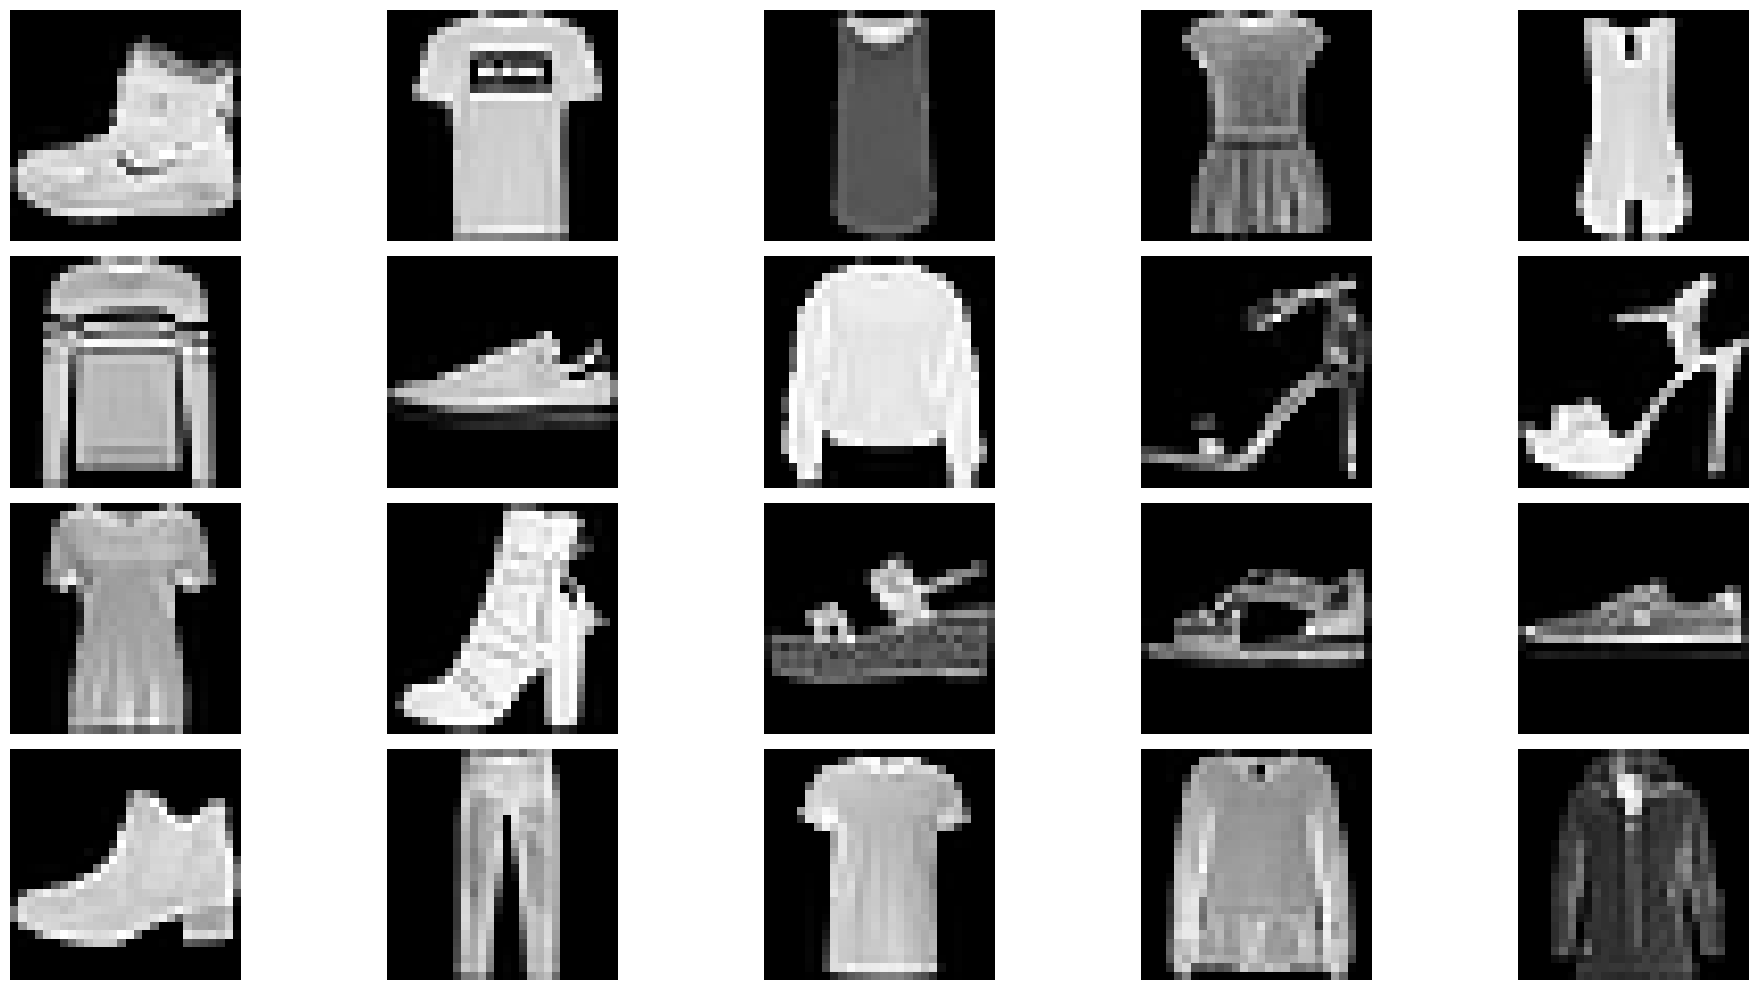

In [29]:
fashion_mnist = keras.datasets.fashion_mnist.load_data()
(X_train_full, y_train_full), (X_test, y_test) = fashion_mnist
X_train_full = X_train_full.astype(np.float32) / 255
X_test = X_test.astype(np.float32) / 255
X_train, X_valid = X_train_full[:-5000], X_train_full[-5000:]
y_train, y_valid = y_train_full[:-5000], y_train_full[-5000:]

print(y_train[:20])
plot_images(X_train[:20], 4, 5)

# Autoencoder

## Single Layer Autoencoder

In [30]:
code_size = 10

base_encoder = keras.models.Sequential(
        [
                keras.layers.Flatten(input_shape=[28, 28]),
                keras.layers.Dense(code_size, activation="relu"),
                ]
        )
base_decoder = keras.models.Sequential(
        [
                keras.layers.Input(shape=[code_size]),
                keras.layers.Dense(28 * 28, activation="sigmoid", input_shape=[code_size]),
                keras.layers.Reshape([28, 28]),
                ]
        )

base_ae = keras.models.Sequential([base_encoder, base_decoder])
base_ae.compile(
        loss="binary_crossentropy",
        optimizer=keras.optimizers.SGD(learning_rate=1.5),
        metrics=[rounded_accuracy],
        jit_compile=True
        )
base_ae.summary()

/Users/thomasbayer/Projects/PycharmProjects/ml/dl_winter/.venv/lib/python3.14/site-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
/Users/thomasbayer/Projects/PycharmProjects/ml/dl_winter/.venv/lib/python3.14/site-packages/keras/src/layers/core/dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_17"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_15 (Sequential)      │ (None, 10)             │         7,850 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_16 (Sequential)      │ (None, 28, 28)         │         8,624 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 16,474 (64.35 KB)

 Trainable params: 16,474 (64.35 KB)

 Non-trainable params: 0 (0.00 B)

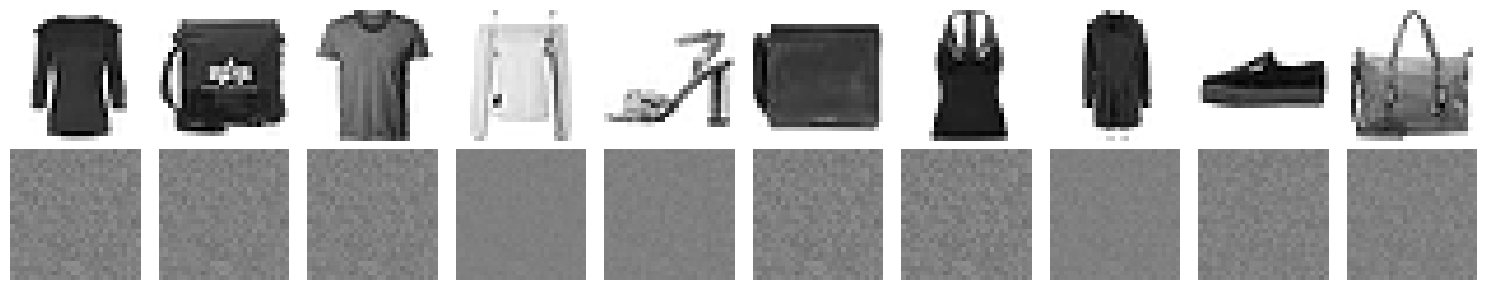

In [11]:
plot_reconstructions(base_ae, images=X_valid[:10], n_images=10)

Epoch 1/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 17s 8ms/step - loss: 0.3889 - rounded_accuracy: 0.8377 - val_loss: 0.3409 - val_rounded_accuracy: 0.8830
Epoch 2/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - loss: 0.3298 - rounded_accuracy: 0.8946 - val_loss: 0.3253 - val_rounded_accuracy: 0.9001
Epoch 3/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - loss: 0.3206 - rounded_accuracy: 0.9040 - val_loss: 0.3211 - val_rounded_accuracy: 0.9068
Epoch 4/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - loss: 0.3182 - rounded_accuracy: 0.9060 - val_loss: 0.3194 - val_rounded_accuracy: 0.9059
Epoch 5/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - loss: 0.3164 - rounded_accuracy: 0.9076 - val_loss: 0.3171 - val_rounded_accuracy: 0.9095
Epoch 6/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - loss: 0.3143 - rounded_accuracy: 0.9097 - val_loss: 0.3156 - val_rounded_accuracy: 0.9102
Epoch 7/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - loss: 0.3134 - rounded_accuracy: 0.9104 - val_loss: 0.3149 - val_ro

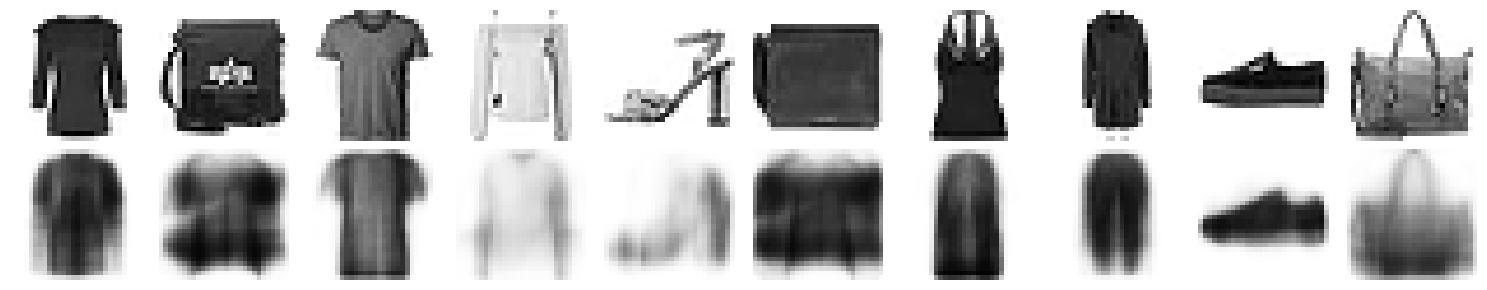

In [15]:
early_stopping = keras.callbacks.EarlyStopping(
        monitor="val_loss",
        mode="min",
        patience=3,
        min_delta=1e-4,
        restore_best_weights=True,
        )
base_ae.fit(
        X_train,
        X_train,
        epochs=20,
        validation_data=(X_valid, X_valid),
        verbose=1,
        callbacks=[early_stopping]
        )
plot_reconstructions(base_ae, images=X_valid[:10], n_images=10)
base_ae.save("../models/base_autoencoder_model.keras")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 150ms/step


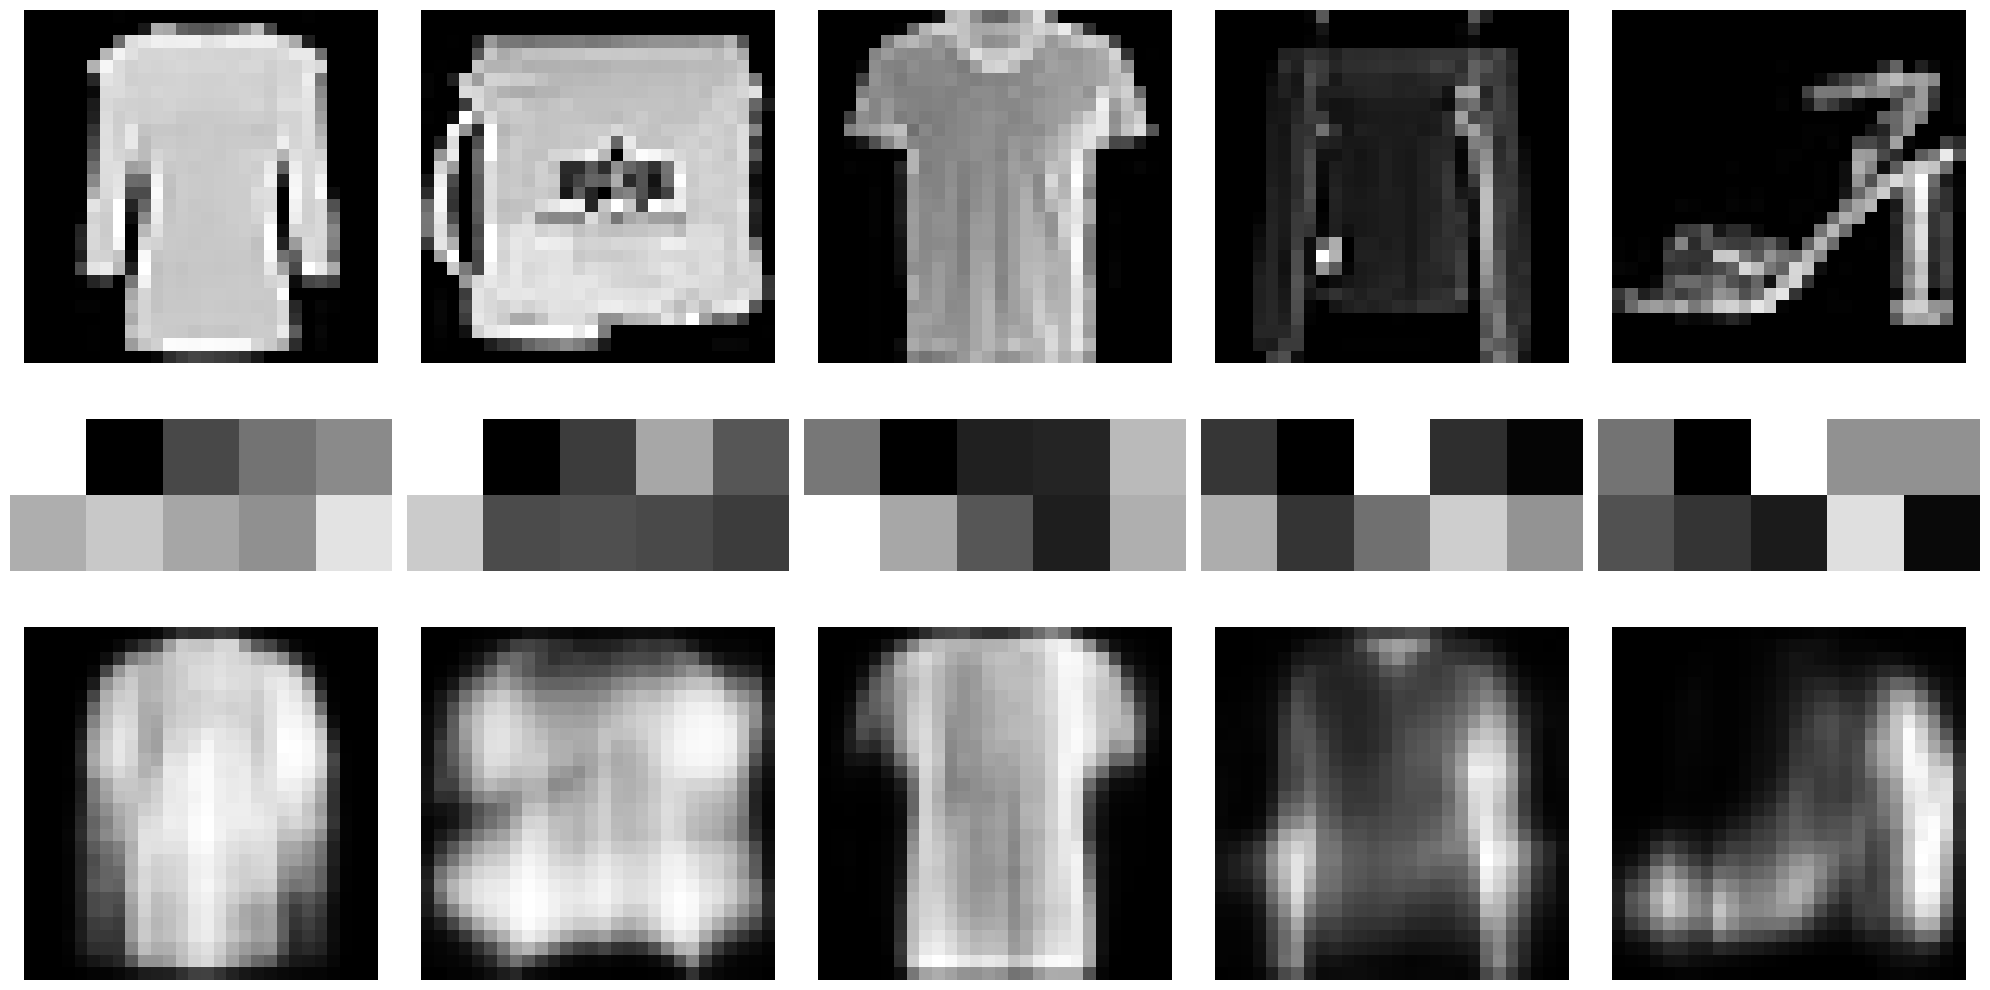

In [16]:
show_reconstructions_code(base_ae, X_valid, (2, 5), 5)

In [7]:
code_size = 10

encoder = keras.models.Sequential(
        [
                keras.layers.Flatten(input_shape=[28, 28]),
                keras.layers.Dense(100, activation="relu"),
                keras.layers.Dense(30, activation="relu"),
                keras.layers.Dense(code_size, activation="relu"),
                ]
        )
decoder = keras.models.Sequential(
        [
                keras.layers.Input(shape=[code_size]),
                keras.layers.Dense(30, activation="relu"),
                keras.layers.Dense(100, activation="relu"),
                keras.layers.Dense(28 * 28, activation="sigmoid", input_shape=[code_size]),
                keras.layers.Reshape([28, 28]),
                ]
        )

autoencoder = keras.models.Sequential([encoder, decoder])
autoencoder.compile(
        loss="binary_crossentropy",
        optimizer=keras.optimizers.SGD(learning_rate=1.5),
        metrics=[rounded_accuracy],
        jit_compile=True
        )
autoencoder.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_3 (Sequential)       │ (None, 10)             │        81,840 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_4 (Sequential)       │ (None, 28, 28)         │        82,614 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 164,454 (642.40 KB)

 Trainable params: 164,454 (642.40 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
1707/1719 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.3851 - rounded_accuracy: 0.8370   

W1115 11:29:44.407000 49783 .venv/lib/python3.14/site-packages/torch/_inductor/utils.py:1806] [1/2_1] Not enough SMs to use max_autotune_gemm mode


1719/1719 ━━━━━━━━━━━━━━━━━━━━ 31s 14ms/step - loss: 0.3848 - rounded_accuracy: 0.8374 - val_loss: 0.3546 - val_rounded_accuracy: 0.8757
Epoch 2/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 14s 8ms/step - loss: 0.3268 - rounded_accuracy: 0.8930 - val_loss: 0.3199 - val_rounded_accuracy: 0.9011
Epoch 3/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - loss: 0.3159 - rounded_accuracy: 0.9034 - val_loss: 0.3164 - val_rounded_accuracy: 0.9020
Epoch 4/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - loss: 0.3108 - rounded_accuracy: 0.9081 - val_loss: 0.3092 - val_rounded_accuracy: 0.9123
Epoch 5/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - loss: 0.3070 - rounded_accuracy: 0.9114 - val_loss: 0.3075 - val_rounded_accuracy: 0.9112
Epoch 6/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 12s 7ms/step - loss: 0.3044 - rounded_accuracy: 0.9135 - val_loss: 0.3045 - val_rounded_accuracy: 0.9159
Epoch 7/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - loss: 0.3027 - rounded_accuracy: 0.9150 - val_loss: 0.3021 - val_rounded_ac

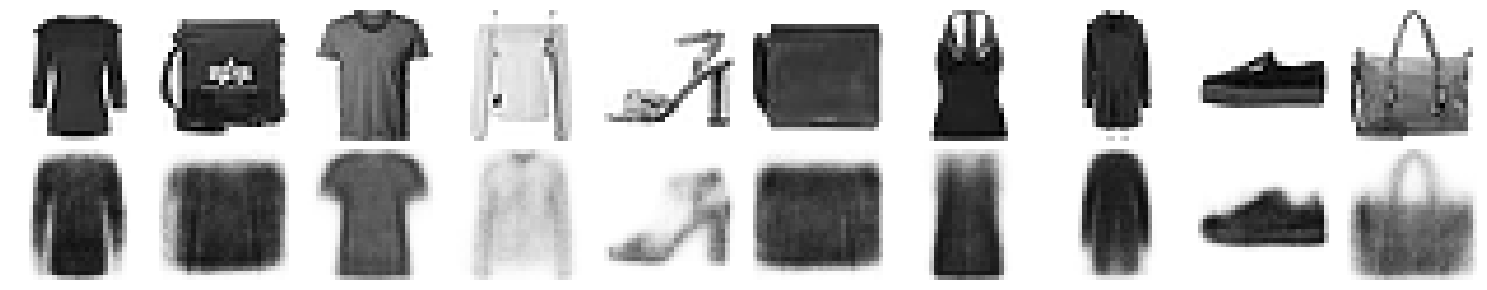

In [8]:
early_stopping = keras.callbacks.EarlyStopping(
        monitor="val_loss",
        mode="min",
        patience=3,
        min_delta=1e-4,
        restore_best_weights=True,
        )
autoencoder.fit(
        X_train,
        X_train,
        epochs=20,
        validation_data=(X_valid, X_valid),
        verbose=1,
        callbacks=[early_stopping]
        )
plot_reconstructions(autoencoder, images=X_valid[:10], n_images=10)
autoencoder.save("../models/autoencoder_model.keras")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 271ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step


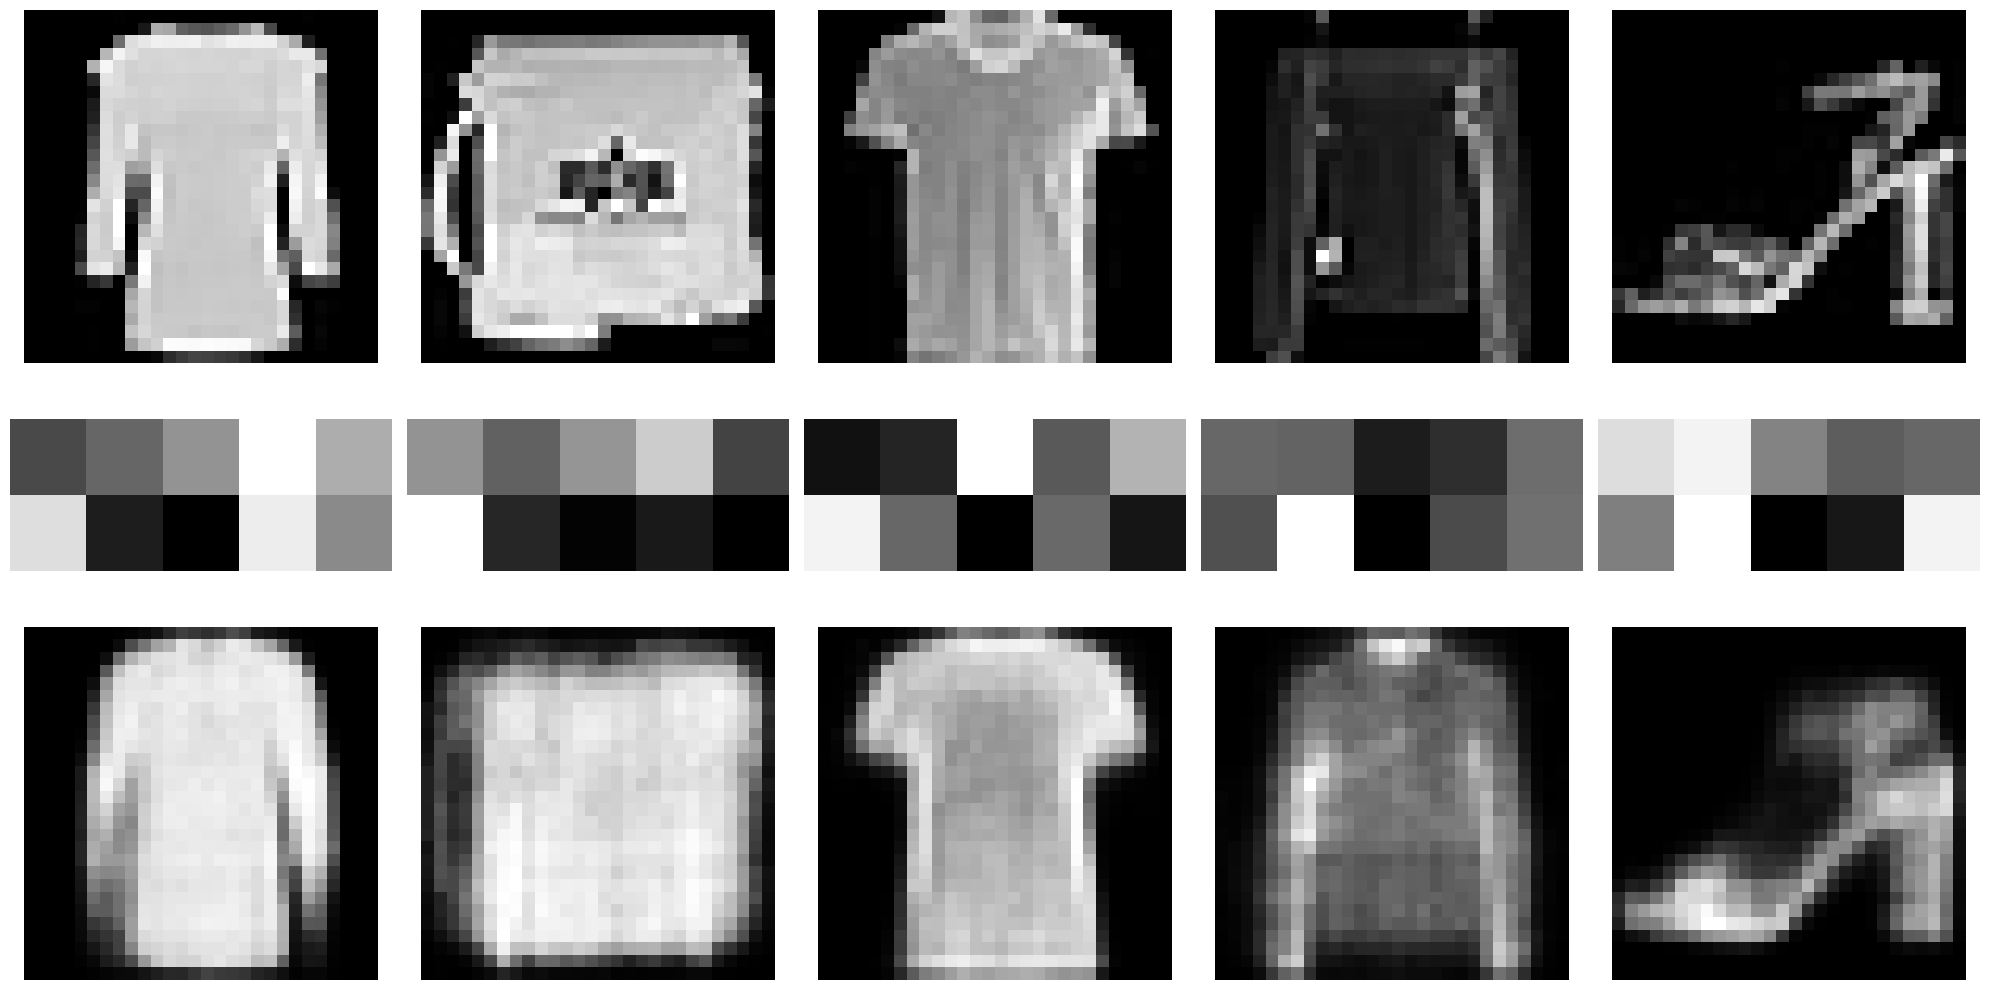

In [19]:
show_reconstructions_code(autoencoder, X_valid, (2, 5), 5)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step


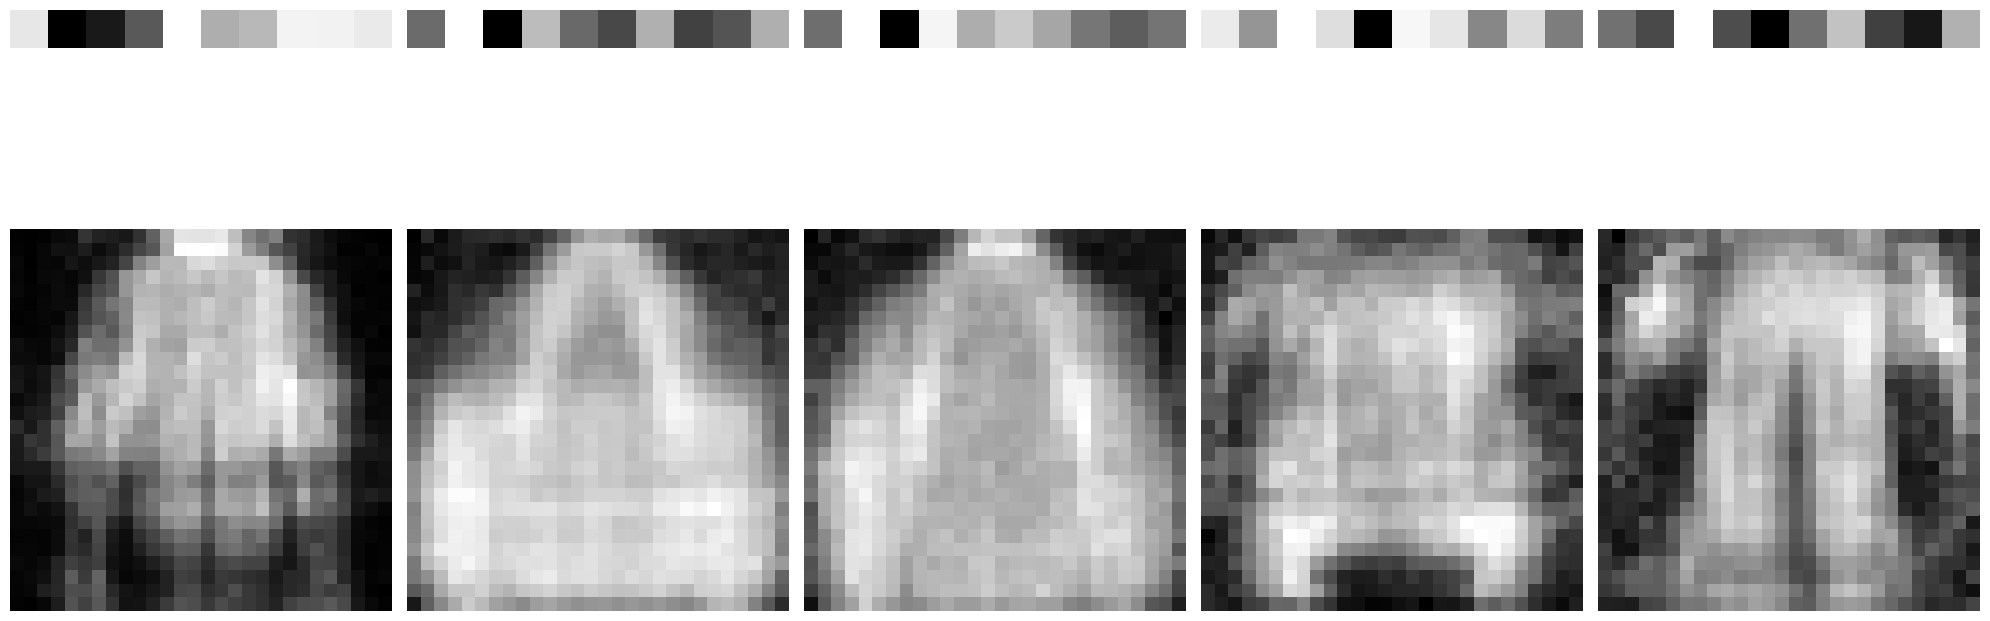

In [24]:
img_codes = encoder.predict(X_valid[:5])
noisy_code = torch.randn_like(torch.tensor(img_codes))
show_code_reconstructions(decoder, noisy_code, 5, (28, 28))

In [27]:
code_size = 49

encoder_max = keras.models.Sequential(
        [
                keras.layers.Flatten(input_shape=[28, 28]),
                keras.layers.Dense(200, activation="relu"),
                keras.layers.Dense(60, activation="relu"),
                keras.layers.Dense(code_size, activation="relu"),
                ]
        )
decoder_max = keras.models.Sequential(
        [
                keras.layers.Input(shape=[code_size]),
                keras.layers.Dense(60, activation="relu"),
                keras.layers.Dense(200, activation="relu"),
                keras.layers.Dense(28 * 28, activation="sigmoid", input_shape=[code_size]),
                keras.layers.Reshape([28, 28]),
                ]
        )

autoencoder_max = keras.models.Sequential([encoder_max, decoder_max])
autoencoder_max.compile(
        loss="binary_crossentropy",
        optimizer=keras.optimizers.SGD(learning_rate=1.5),
        metrics=[rounded_accuracy],
        jit_compile=True
        )
autoencoder_max.summary()

Model: "sequential_20"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_18 (Sequential)      │ (None, 49)             │       172,049 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_19 (Sequential)      │ (None, 28, 28)         │       172,784 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 344,833 (1.32 MB)

 Trainable params: 344,833 (1.32 MB)

 Non-trainable params: 0 (0.00 B)

In [15]:
def train(autoencoder, X_train, X_valid, epochs=20, batch_size=32, filename=None, shape=(2, 5)):
    early_stopping = keras.callbacks.EarlyStopping(
            monitor="val_loss",
            mode="min",
            patience=3,
            min_delta=1e-4,
            restore_best_weights=True,
            )
    history = autoencoder.fit(
            X_train,
            X_train,
            epochs=epochs,
            batch_size=batch_size,
            validation_data=(X_valid, X_valid),
            verbose=1,
            callbacks=[early_stopping]
            )
    show_reconstructions_code(autoencoder, X_valid[:5], shape, 5)
    loss, accuracy = autoencoder.evaluate(X_valid, X_valid, verbose=2)
    print(f"Validation loss: {loss:.4f}, Validation accuracy: {accuracy:.4f}")
    if filename is not None:
        autoencoder.save(filename)
    return history


train(
        autoencoder_max,
        X_train,
        X_valid,
        epochs=20,
        batch_size=32,
        shape=(7, 7),
        filename="../models/autoencoder_max_model.keras"
        )

NameError: name 'autoencoder_max' is not defined

In [ ]:
plot_reconstructions(autoencoder, images=X_valid[:10], n_images=10)

## Denoising Autoencoder

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step


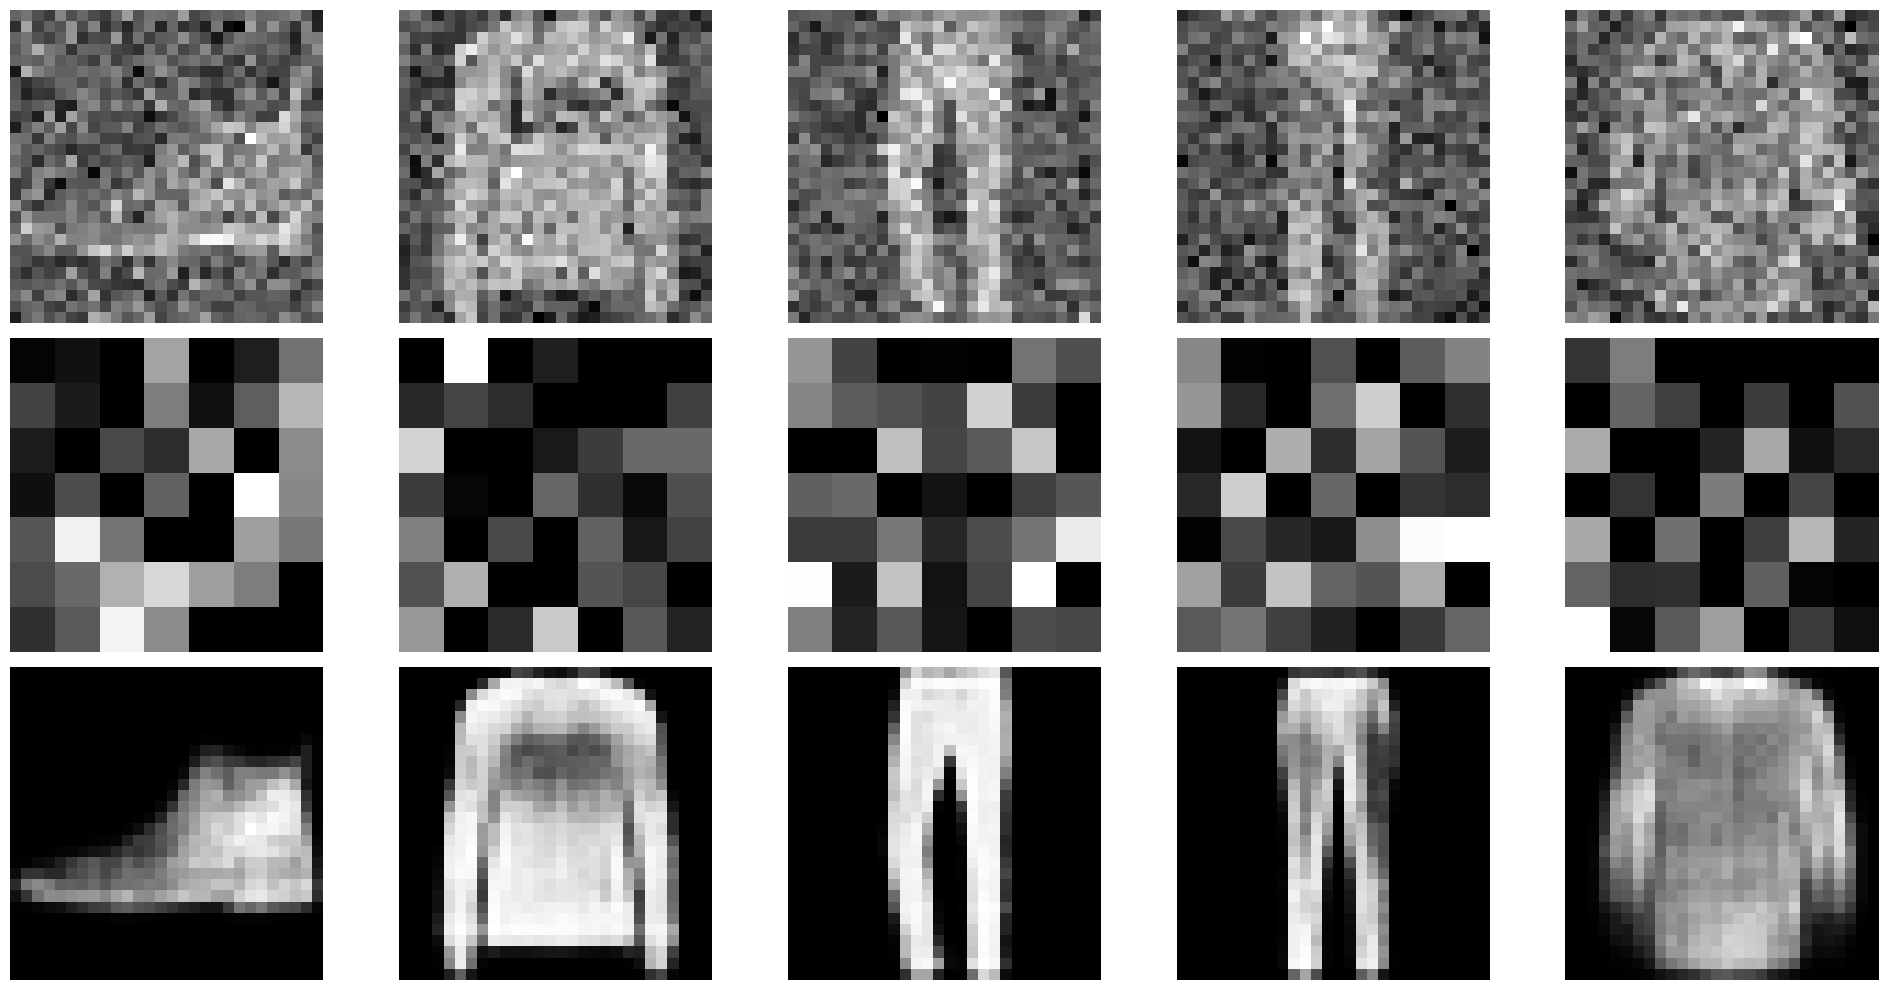

In [30]:
noise_layer = keras.layers.GaussianNoise(0.3)
noisy_images = noise_layer(X_test, training=True).to("cpu")
show_reconstructions_code(autoencoder_max, noisy_images, (7, 7), 5)

In [31]:
code_size = 10

encoder2 = keras.models.Sequential(
        [
                keras.layers.GaussianNoise(0.3),
                keras.layers.Flatten(input_shape=[28, 28]),
                keras.layers.Dense(100, activation="relu"),
                keras.layers.Dense(30, activation="relu"),
                keras.layers.Dense(code_size, activation="relu"),
                ]
        )

decoder2 = keras.models.Sequential(
        [
                keras.layers.Input(shape=[code_size]),
                keras.layers.Dense(30, activation="relu"),
                keras.layers.Dense(100, activation="relu"),
                keras.layers.Dense(28 * 28, activation="sigmoid", input_shape=[code_size]),
                keras.layers.Reshape([28, 28]),
                ]
        )

denoising_ae = keras.models.Sequential([encoder2, decoder2])
denoising_ae.compile(
        loss="binary_crossentropy",
        optimizer=keras.optimizers.SGD(learning_rate=1.5),
        metrics=[rounded_accuracy],
        jit_compile=True
        )
denoising_ae.summary()

/Users/thomasbayer/Projects/PycharmProjects/ml/dl_winter/.venv/lib/python3.14/site-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
/Users/thomasbayer/Projects/PycharmProjects/ml/dl_winter/.venv/lib/python3.14/site-packages/keras/src/layers/core/dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_23"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_21 (Sequential)      │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_22 (Sequential)      │ (None, 28, 28)         │        82,614 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 82,614 (322.71 KB)

 Trainable params: 82,614 (322.71 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
860/860 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.4197 - rounded_accuracy: 0.7985

W1109 16:08:50.859000 7384 .venv/lib/python3.14/site-packages/torch/_dynamo/convert_frame.py:2008] [17/9] torch._dynamo hit config.recompile_limit (8)
W1109 16:08:50.859000 7384 .venv/lib/python3.14/site-packages/torch/_dynamo/convert_frame.py:2008] [17/9]    function: 'one_step_on_data' (/Users/thomasbayer/Projects/PycharmProjects/ml/dl_winter/.venv/lib/python3.14/site-packages/keras/src/backend/torch/trainer.py:142)
W1109 16:08:50.859000 7384 .venv/lib/python3.14/site-packages/torch/_dynamo/convert_frame.py:2008] [17/9]    last reason: 17/8: tensor 'data[0][0]' size mismatch at index 0. expected 8, actual 64
W1109 16:08:50.859000 7384 .venv/lib/python3.14/site-packages/torch/_dynamo/convert_frame.py:2008] [17/9] To log all recompilation reasons, use TORCH_LOGS="recompiles".
W1109 16:08:50.859000 7384 .venv/lib/python3.14/site-packages/torch/_dynamo/convert_frame.py:2008] [17/9] To diagnose recompilation issues, see https://docs.pytorch.org/docs/main/user_guide/torch_compiler/compile/

860/860 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step - loss: 0.4197 - rounded_accuracy: 0.7985 - val_loss: 0.3660 - val_rounded_accuracy: 0.8537
Epoch 2/20
860/860 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step - loss: 0.3528 - rounded_accuracy: 0.8688 - val_loss: 0.3424 - val_rounded_accuracy: 0.8795
Epoch 3/20
860/860 ━━━━━━━━━━━━━━━━━━━━ 9s 10ms/step - loss: 0.3338 - rounded_accuracy: 0.8877 - val_loss: 0.3494 - val_rounded_accuracy: 0.8773
Epoch 4/20
860/860 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - loss: 0.3244 - rounded_accuracy: 0.8963 - val_loss: 0.3315 - val_rounded_accuracy: 0.8929
Epoch 5/20
860/860 ━━━━━━━━━━━━━━━━━━━━ 9s 10ms/step - loss: 0.3197 - rounded_accuracy: 0.9008 - val_loss: 0.3162 - val_rounded_accuracy: 0.9061
Epoch 6/20
860/860 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step - loss: 0.3162 - rounded_accuracy: 0.9037 - val_loss: 0.3136 - val_rounded_accuracy: 0.9084
Epoch 7/20
860/860 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step - loss: 0.3133 - rounded_accuracy: 0.9064 - val_loss: 0.3101 - val_rounded_accuracy: 0.9107
E

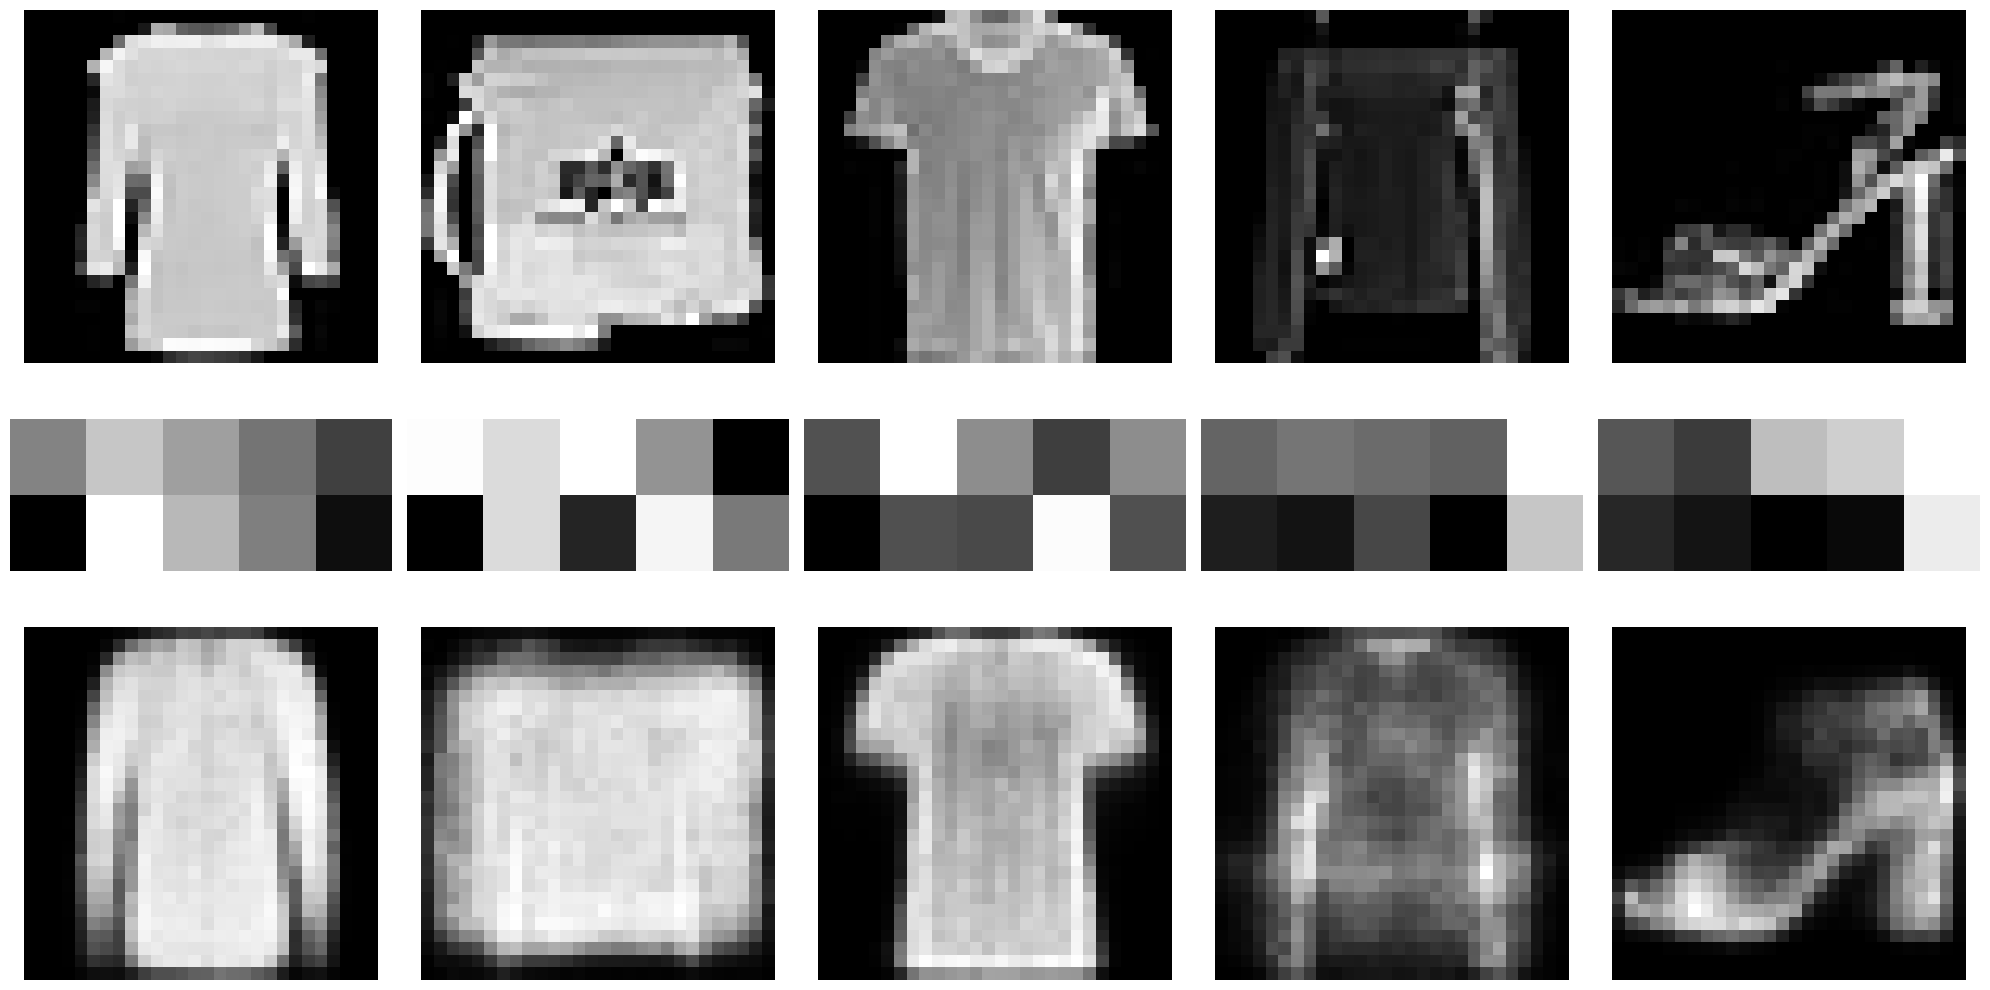

157/157 - 1s - 5ms/step - loss: 0.2975 - rounded_accuracy: 0.9233
Validation loss: 0.2975, Validation accuracy: 0.9233


In [32]:
train(
        denoising_ae, X_train, X_valid, epochs=20, batch_size=64,
        filename="../models/denoising_autoencoder_model.keras"
        )

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step


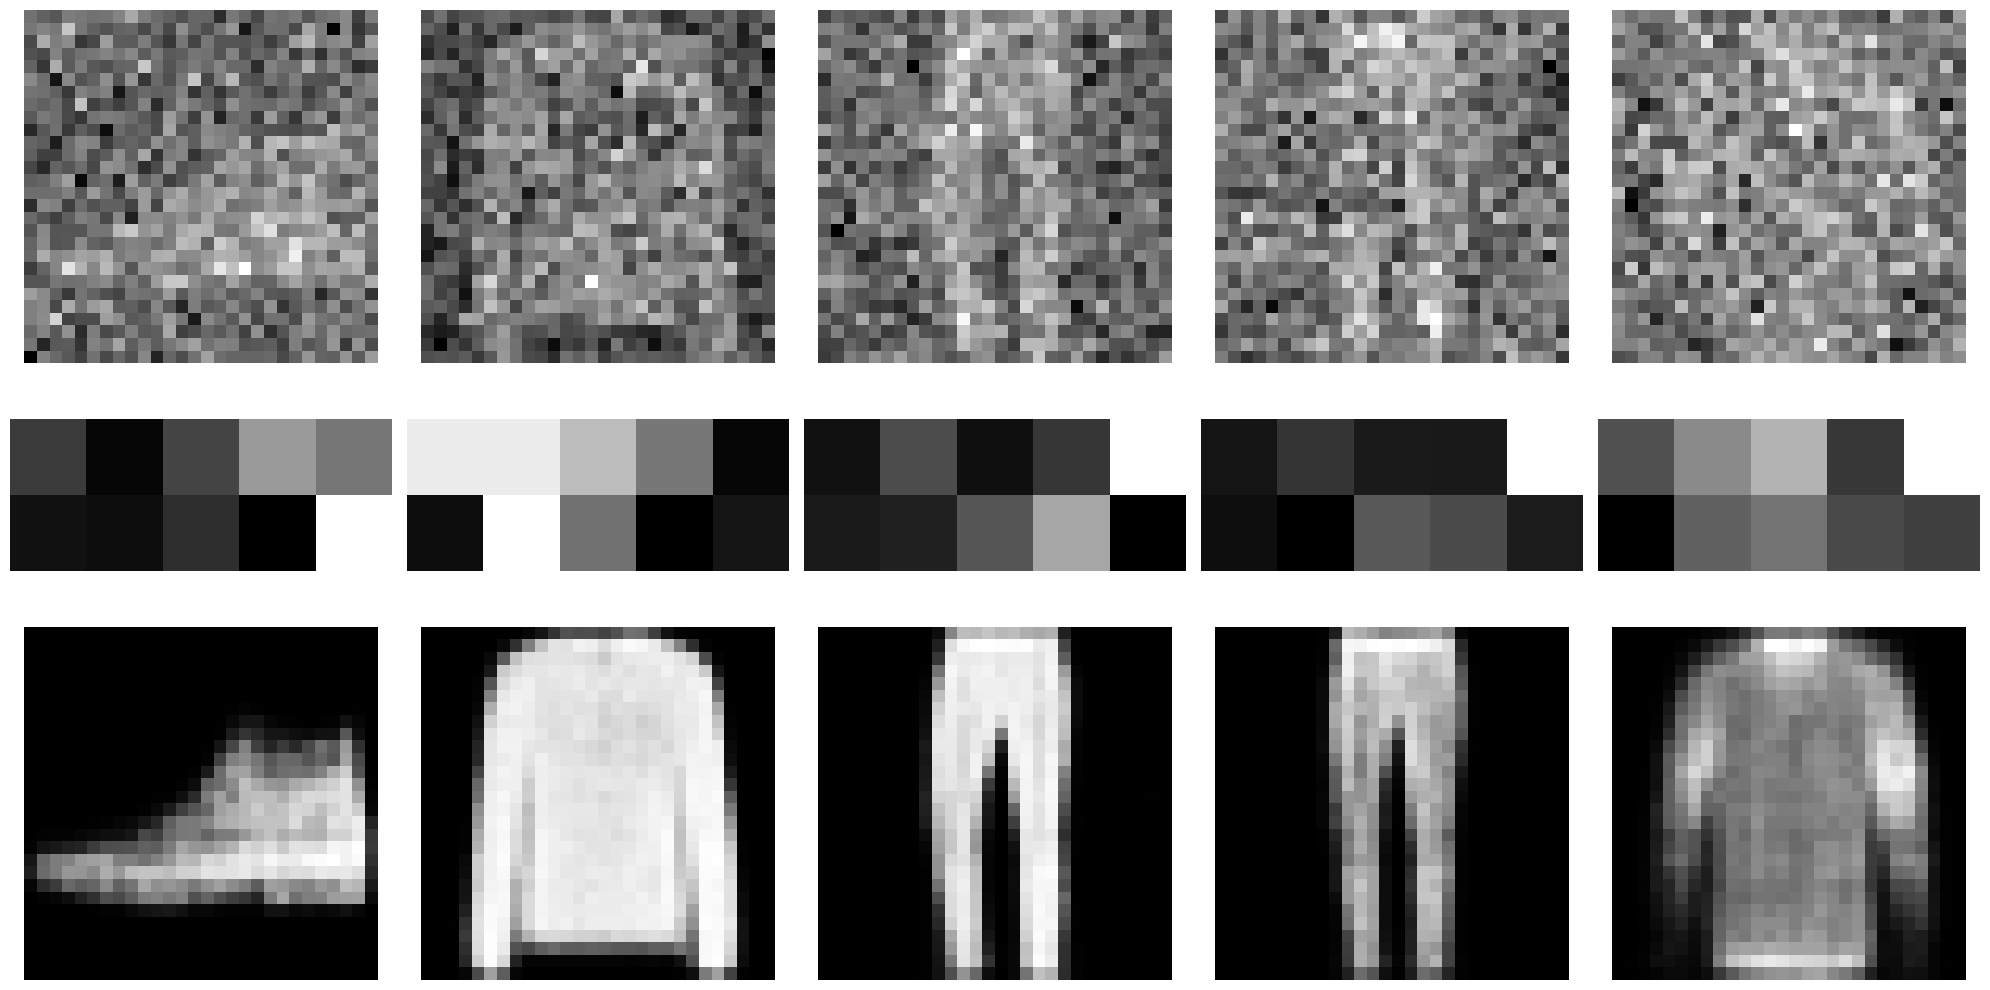

In [37]:
noise = keras.layers.GaussianNoise(0.5)
img_noise = noise(X_test, training=True).to("cpu")
show_reconstructions_code(denoising_ae, img_noise, (2, 5), 5)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step


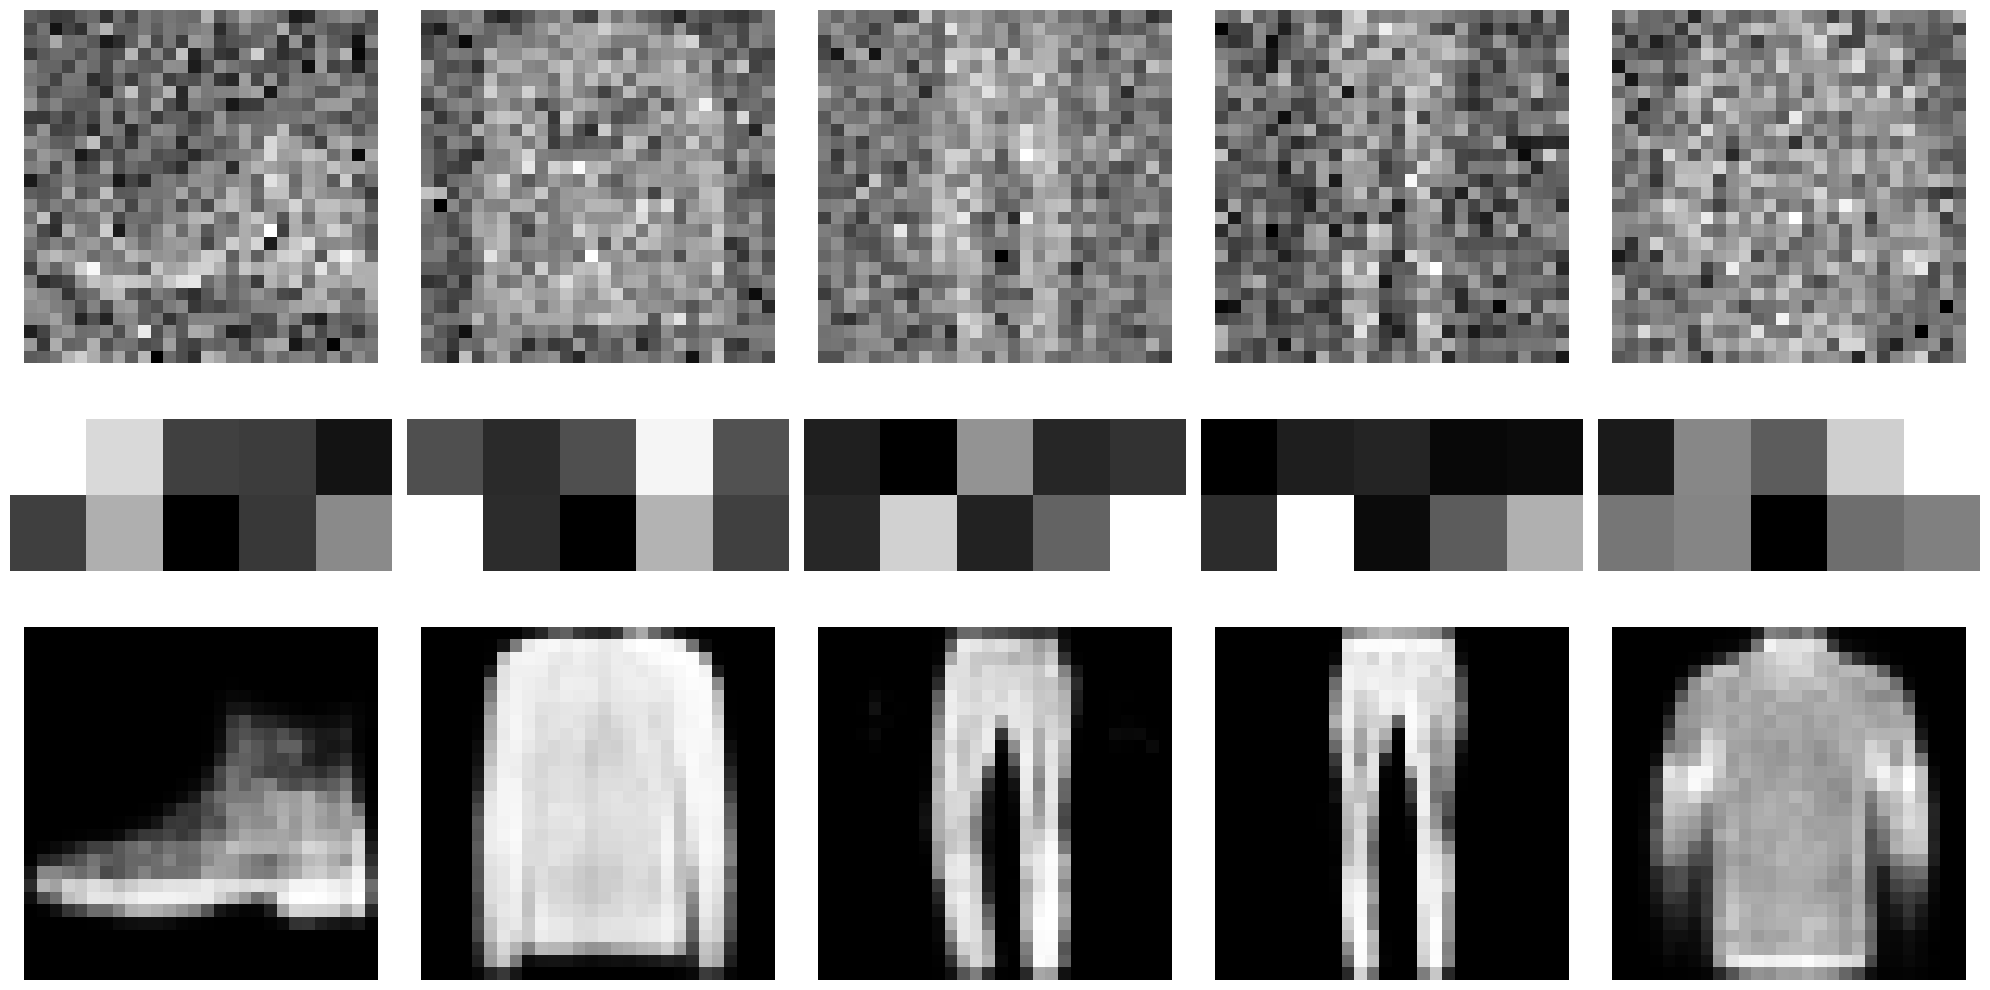

In [38]:
noise = keras.layers.GaussianNoise(0.5)
img_noise = noise(X_test, training=True).to("cpu")
show_reconstructions_code(autoencoder, img_noise, (2, 5), 5)

## Erasing Autoencoder

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step


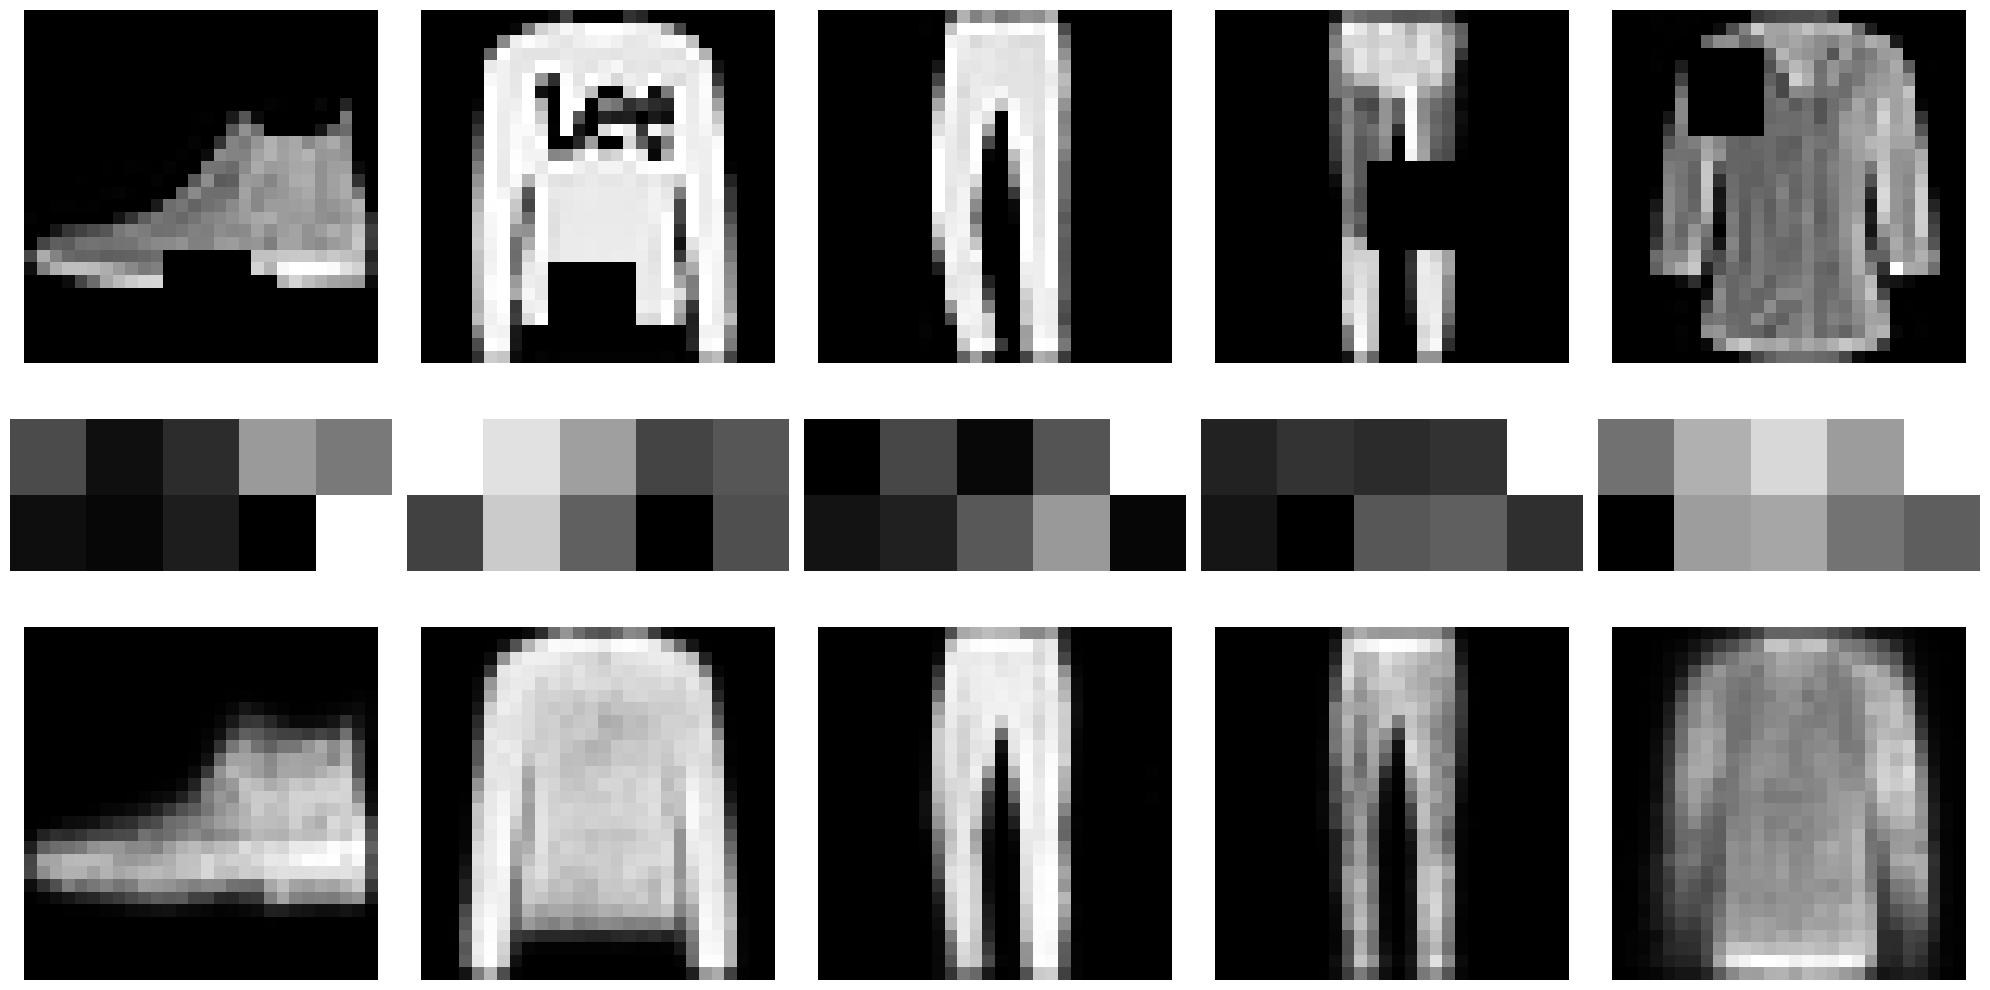

In [42]:
eraser = keras.layers.RandomErasing(
        factor=(1.0, 1.0),
        scale=(0.05, 0.06),
        fill_value=0,
        value_range=(0, 1),
        data_format="channels_last",
        )

# (N, 28, 28) -> (N, 28, 28, 1)
erased_imgs = eraser(X_test[..., None], training=True)

# Remove channel axis for the autoencoder
erased_imgs = erased_imgs[..., 0].to("cpu")

show_reconstructions_code(denoising_ae, erased_imgs, (2, 5), 5)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


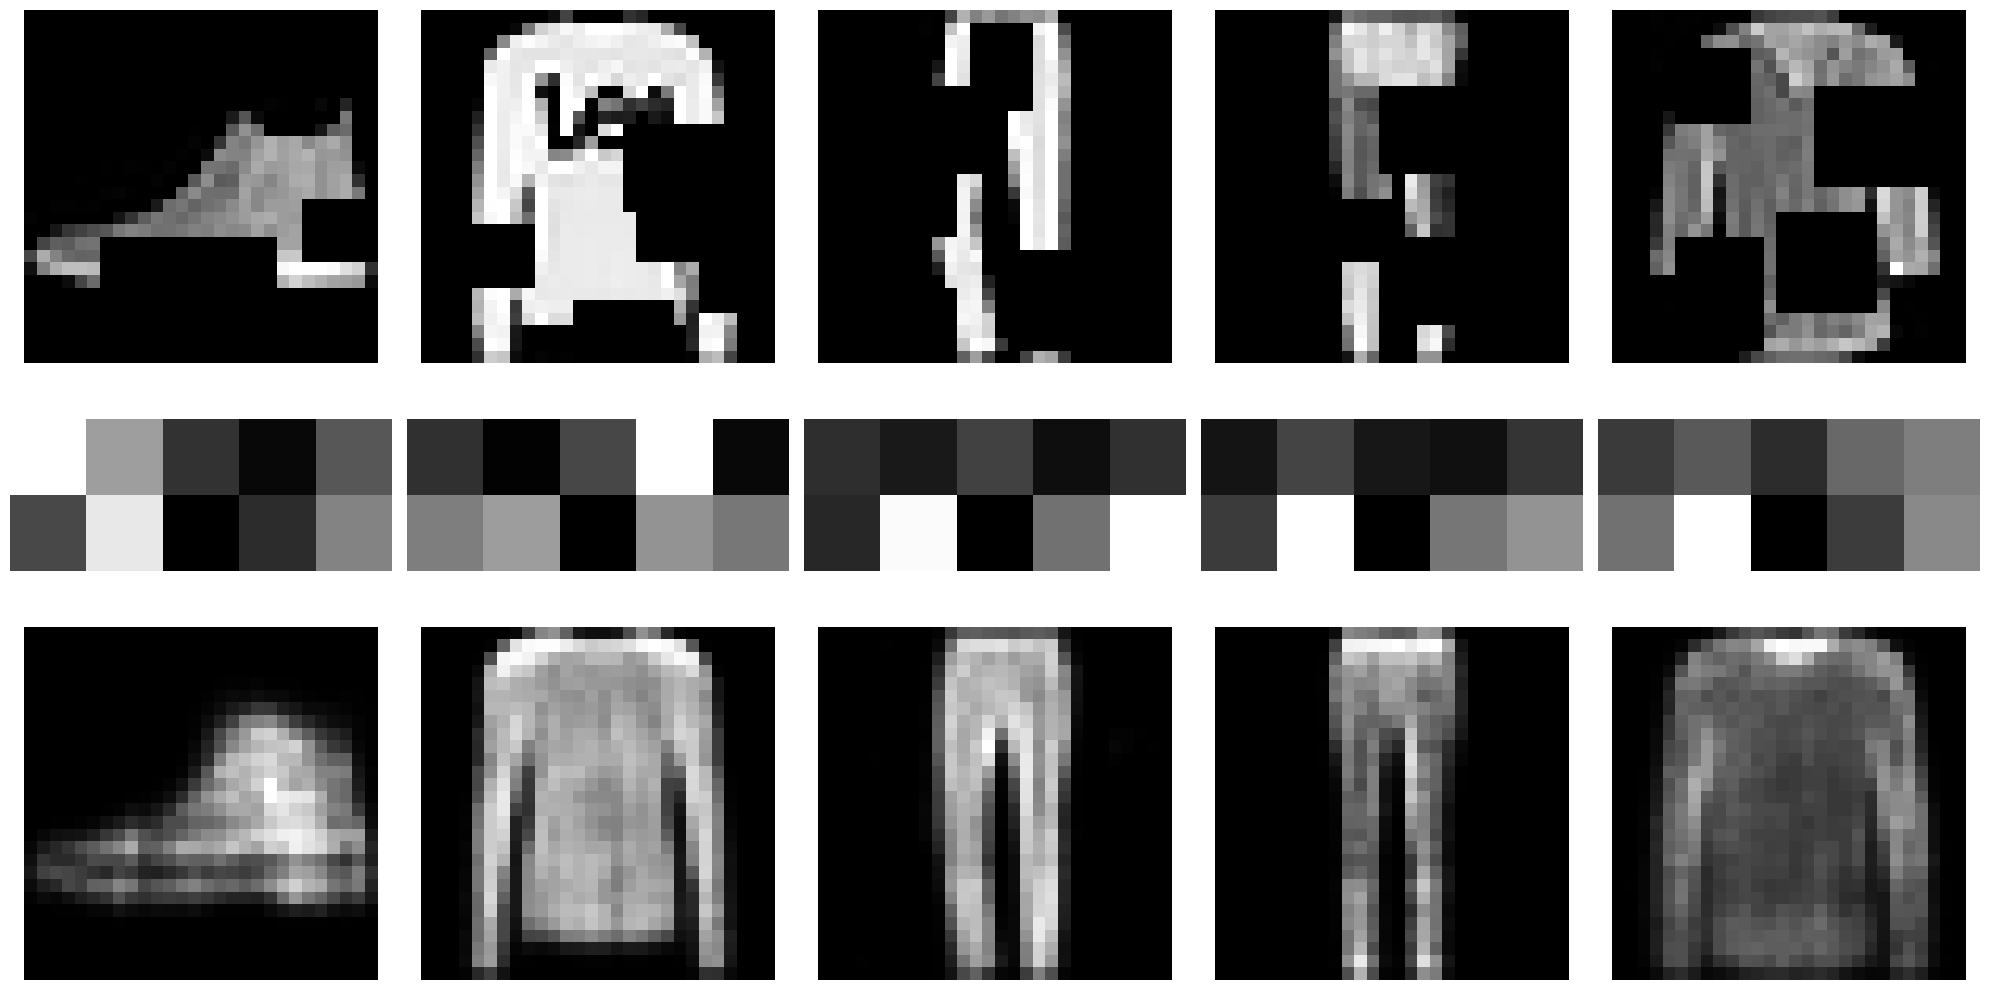

In [60]:
eraser = keras.layers.RandomErasing(
        factor=(1.0, 1.0),
        scale=(0.03, 0.08),
        fill_value=0,
        value_range=(0, 1),
        data_format="channels_last",
        )

# (N, 28, 28) -> (N, 28, 28, 1)
erased_imgs = X_test[..., None]
for _ in range(6):
    erased_imgs = eraser(erased_imgs, training=True)

# Remove channel axis for the autoencoder
erased_imgs = erased_imgs[..., 0].to("cpu")

show_reconstructions_code(autoencoder, erased_imgs, (2, 5), 5)

In [53]:
code_size = 10

reconstruction_encoder = keras.models.Sequential(
        [
                keras.layers.RandomErasing(
                        factor=(1.0, 1.0),
                        scale=(0.1, 0.2),
                        fill_value=0,
                        value_range=(0, 1)
                        ),
                keras.layers.RandomErasing(
                        factor=(1.0, 1.0),
                        scale=(0.1, 0.2),
                        fill_value=0,
                        value_range=(0, 1)
                        ),
                keras.layers.Flatten(input_shape=[28, 28]),
                keras.layers.Dense(100, activation="relu"),
                keras.layers.Dense(30, activation="relu"),
                keras.layers.Dense(code_size, activation="relu"),
                ]
        )
reconstruction_decoder = keras.models.Sequential(
        [
                keras.layers.Input(shape=[code_size]),
                keras.layers.Dense(30, activation="relu"),
                keras.layers.Dense(100, activation="relu"),
                keras.layers.Dense(28 * 28, activation="sigmoid", input_shape=[code_size]),
                keras.layers.Reshape([28, 28]),
                ]
        )

reconstruction_ae = keras.models.Sequential([reconstruction_encoder, reconstruction_decoder])
reconstruction_ae.compile(
        loss="binary_crossentropy",
        optimizer=keras.optimizers.SGD(learning_rate=1.5),
        metrics=[rounded_accuracy],
        jit_compile=True
        )
reconstruction_ae.summary()

Model: "sequential_26"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_24 (Sequential)      │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_25 (Sequential)      │ (None, 28, 28)         │        82,614 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 82,614 (322.71 KB)

 Trainable params: 82,614 (322.71 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
860/860 ━━━━━━━━━━━━━━━━━━━━ 16s 18ms/step - loss: 0.4245 - rounded_accuracy: 0.7915 - val_loss: 0.3729 - val_rounded_accuracy: 0.8459
Epoch 2/20
860/860 ━━━━━━━━━━━━━━━━━━━━ 15s 18ms/step - loss: 0.3637 - rounded_accuracy: 0.8548 - val_loss: 0.3458 - val_rounded_accuracy: 0.8777
Epoch 3/20
860/860 ━━━━━━━━━━━━━━━━━━━━ 14s 16ms/step - loss: 0.3497 - rounded_accuracy: 0.8702 - val_loss: 0.3427 - val_rounded_accuracy: 0.8824
Epoch 4/20
860/860 ━━━━━━━━━━━━━━━━━━━━ 14s 16ms/step - loss: 0.3403 - rounded_accuracy: 0.8806 - val_loss: 0.3316 - val_rounded_accuracy: 0.8940
Epoch 5/20
860/860 ━━━━━━━━━━━━━━━━━━━━ 12s 14ms/step - loss: 0.3341 - rounded_accuracy: 0.8865 - val_loss: 0.3249 - val_rounded_accuracy: 0.8983
Epoch 6/20
860/860 ━━━━━━━━━━━━━━━━━━━━ 14s 16ms/step - loss: 0.3306 - rounded_accuracy: 0.8897 - val_loss: 0.3279 - val_rounded_accuracy: 0.8883
Epoch 7/20
860/860 ━━━━━━━━━━━━━━━━━━━━ 15s 17ms/step - loss: 0.3278 - rounded_accuracy: 0.8926 - val_loss: 0.3189 - val_rou

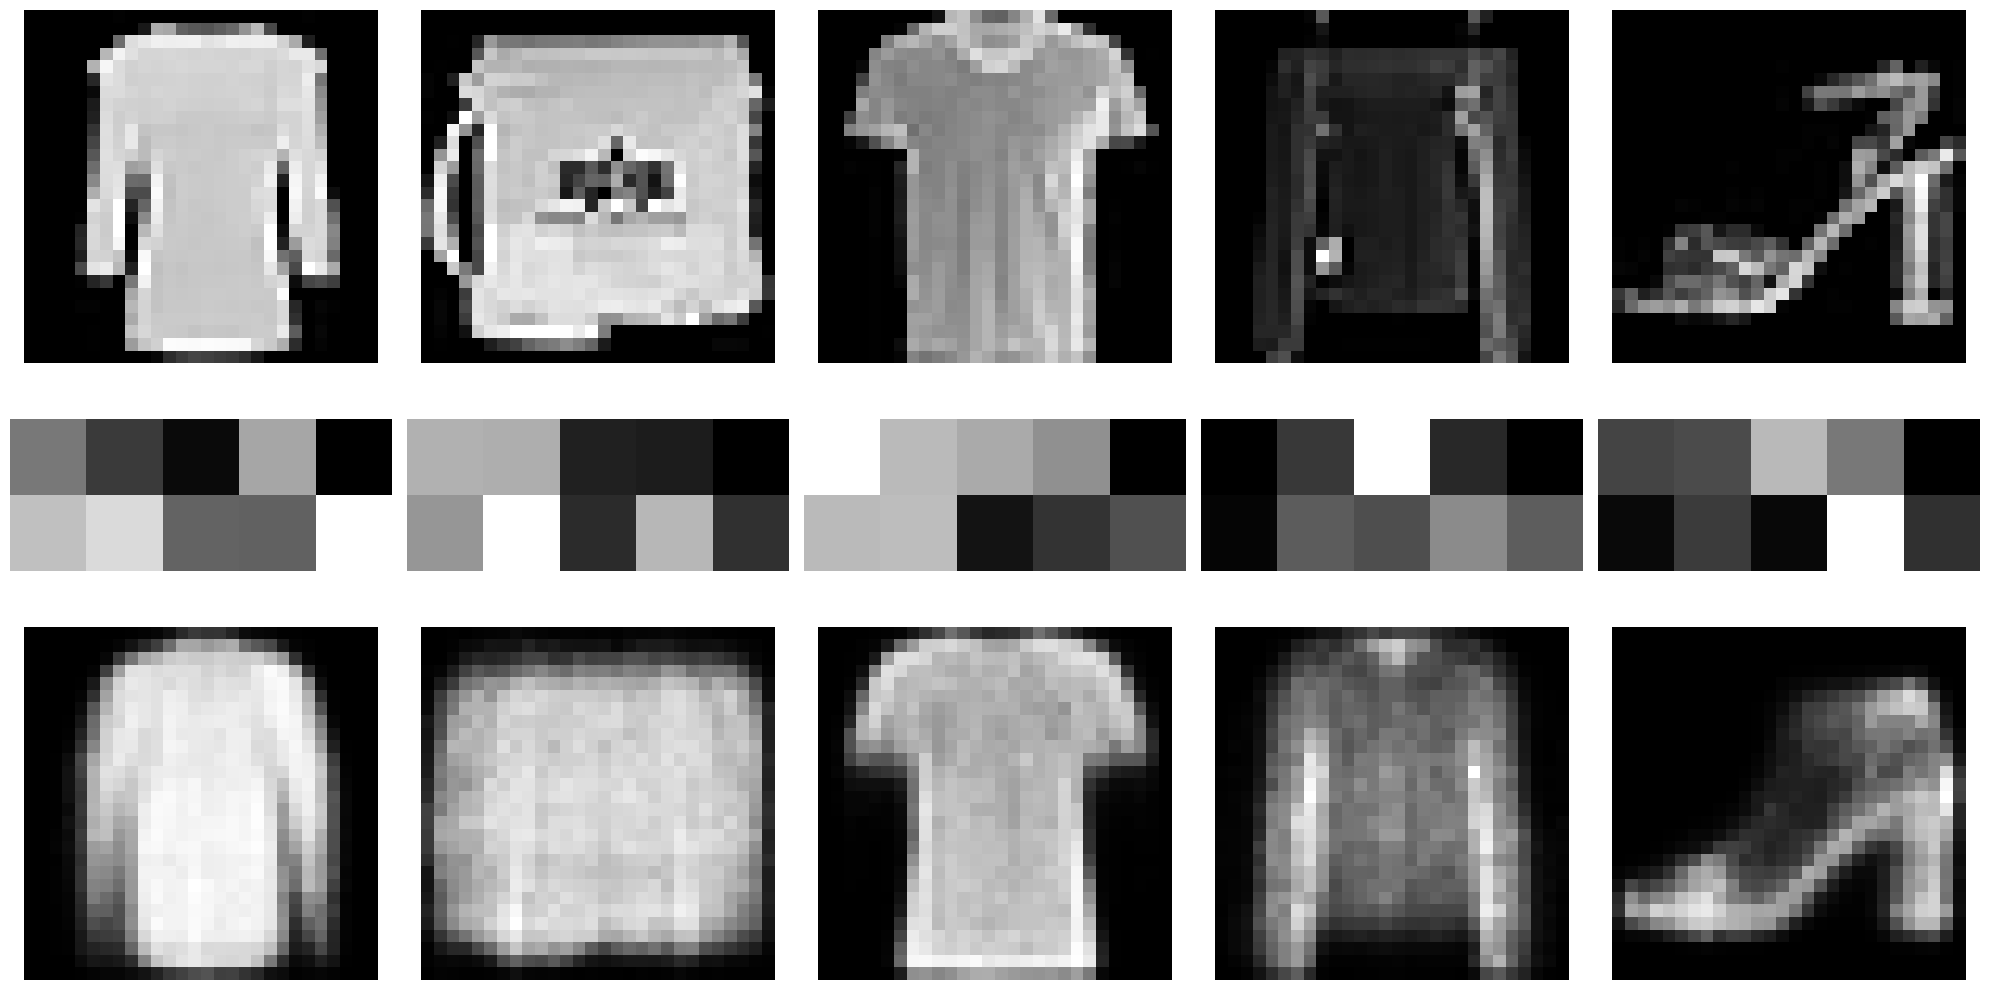

157/157 - 1s - 5ms/step - loss: 0.3036 - rounded_accuracy: 0.9156
Validation loss: 0.3036, Validation accuracy: 0.9156


In [54]:
train(
        reconstruction_ae, X_train, X_valid, epochs=20, batch_size=64,
        filename="../models/reconstruction_autoencoder_model.keras"
        )

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step


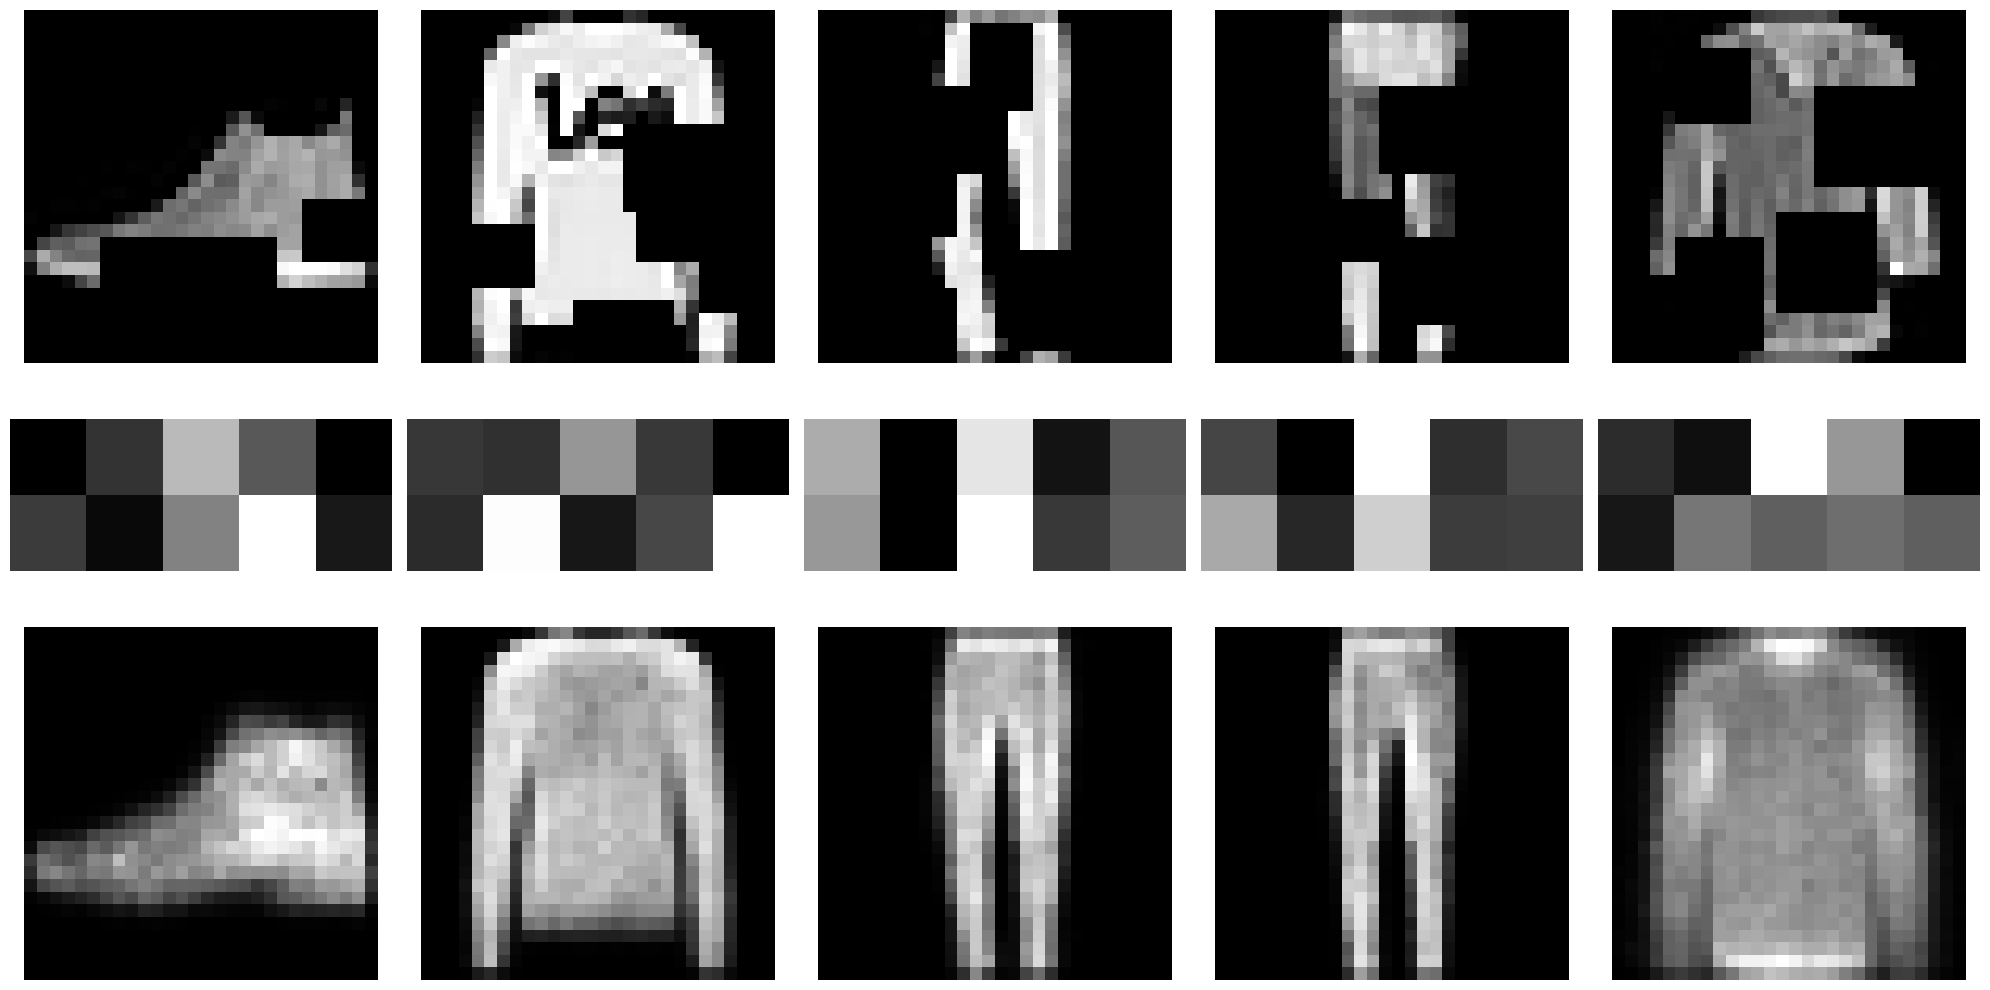

In [61]:
show_reconstructions_code(reconstruction_ae, erased_imgs, (2, 5), 5)

In [23]:
code_size = 2

encoder_2d = keras.models.Sequential(
        [
                keras.layers.Flatten(input_shape=[28, 28]),
                keras.layers.Dense(100, activation="relu"),
                keras.layers.Dense(30, activation="relu"),
                keras.layers.Dense(code_size, activation="relu"),
                ]
        )
decoder_2d = keras.models.Sequential(
        [
                keras.layers.Input(shape=[code_size]),
                keras.layers.Dense(30, activation="relu"),
                keras.layers.Dense(100, activation="relu"),
                keras.layers.Dense(28 * 28, activation="sigmoid", input_shape=[code_size]),
                keras.layers.Reshape([28, 28]),
                ]
        )

ae_2d = keras.models.Sequential([encoder_2d, decoder_2d])
ae_2d.compile(
        loss="binary_crossentropy",
        optimizer=keras.optimizers.SGD(learning_rate=1.5),
        metrics=[rounded_accuracy],
        jit_compile=True
        )
ae_2d.summary()

/Users/thomasbayer/Projects/PycharmProjects/ml/dl_winter/.venv/lib/python3.14/site-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
/Users/thomasbayer/Projects/PycharmProjects/ml/dl_winter/.venv/lib/python3.14/site-packages/keras/src/layers/core/dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_14"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_12 (Sequential)      │ (None, 2)              │        81,592 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_13 (Sequential)      │ (None, 28, 28)         │        82,374 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 163,966 (640.49 KB)

 Trainable params: 163,966 (640.49 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
860/860 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.4822 - rounded_accuracy: 0.7298 

W1115 11:50:31.898000 49783 .venv/lib/python3.14/site-packages/torch/_dynamo/convert_frame.py:2008] [16/8] torch._dynamo hit config.recompile_limit (8)
W1115 11:50:31.898000 49783 .venv/lib/python3.14/site-packages/torch/_dynamo/convert_frame.py:2008] [16/8]    function: 'one_step_on_data' (/Users/thomasbayer/Projects/PycharmProjects/ml/dl_winter/.venv/lib/python3.14/site-packages/keras/src/backend/torch/trainer.py:142)
W1115 11:50:31.898000 49783 .venv/lib/python3.14/site-packages/torch/_dynamo/convert_frame.py:2008] [16/8]    last reason: 16/7: tensor 'data[0][0]' size mismatch at index 0. expected 64, actual 8
W1115 11:50:31.898000 49783 .venv/lib/python3.14/site-packages/torch/_dynamo/convert_frame.py:2008] [16/8] To log all recompilation reasons, use TORCH_LOGS="recompiles".
W1115 11:50:31.898000 49783 .venv/lib/python3.14/site-packages/torch/_dynamo/convert_frame.py:2008] [16/8] To diagnose recompilation issues, see https://docs.pytorch.org/docs/main/user_guide/torch_compiler/com

860/860 ━━━━━━━━━━━━━━━━━━━━ 16s 18ms/step - loss: 0.4822 - rounded_accuracy: 0.7298 - val_loss: 0.4516 - val_rounded_accuracy: 0.7554
Epoch 2/20
860/860 ━━━━━━━━━━━━━━━━━━━━ 13s 16ms/step - loss: 0.4403 - rounded_accuracy: 0.7730 - val_loss: 0.4093 - val_rounded_accuracy: 0.8065
Epoch 3/20
860/860 ━━━━━━━━━━━━━━━━━━━━ 13s 15ms/step - loss: 0.3763 - rounded_accuracy: 0.8463 - val_loss: 0.3928 - val_rounded_accuracy: 0.8421
Epoch 4/20
860/860 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step - loss: 0.3583 - rounded_accuracy: 0.8666 - val_loss: 0.3706 - val_rounded_accuracy: 0.8624
Epoch 5/20
860/860 ━━━━━━━━━━━━━━━━━━━━ 9s 10ms/step - loss: 0.3531 - rounded_accuracy: 0.8724 - val_loss: 0.3532 - val_rounded_accuracy: 0.8729
Epoch 6/20
860/860 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step - loss: 0.3499 - rounded_accuracy: 0.8754 - val_loss: 0.3508 - val_rounded_accuracy: 0.8778
Epoch 7/20
860/860 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step - loss: 0.3474 - rounded_accuracy: 0.8778 - val_loss: 0.3488 - val_rounded_accuracy: 0.8

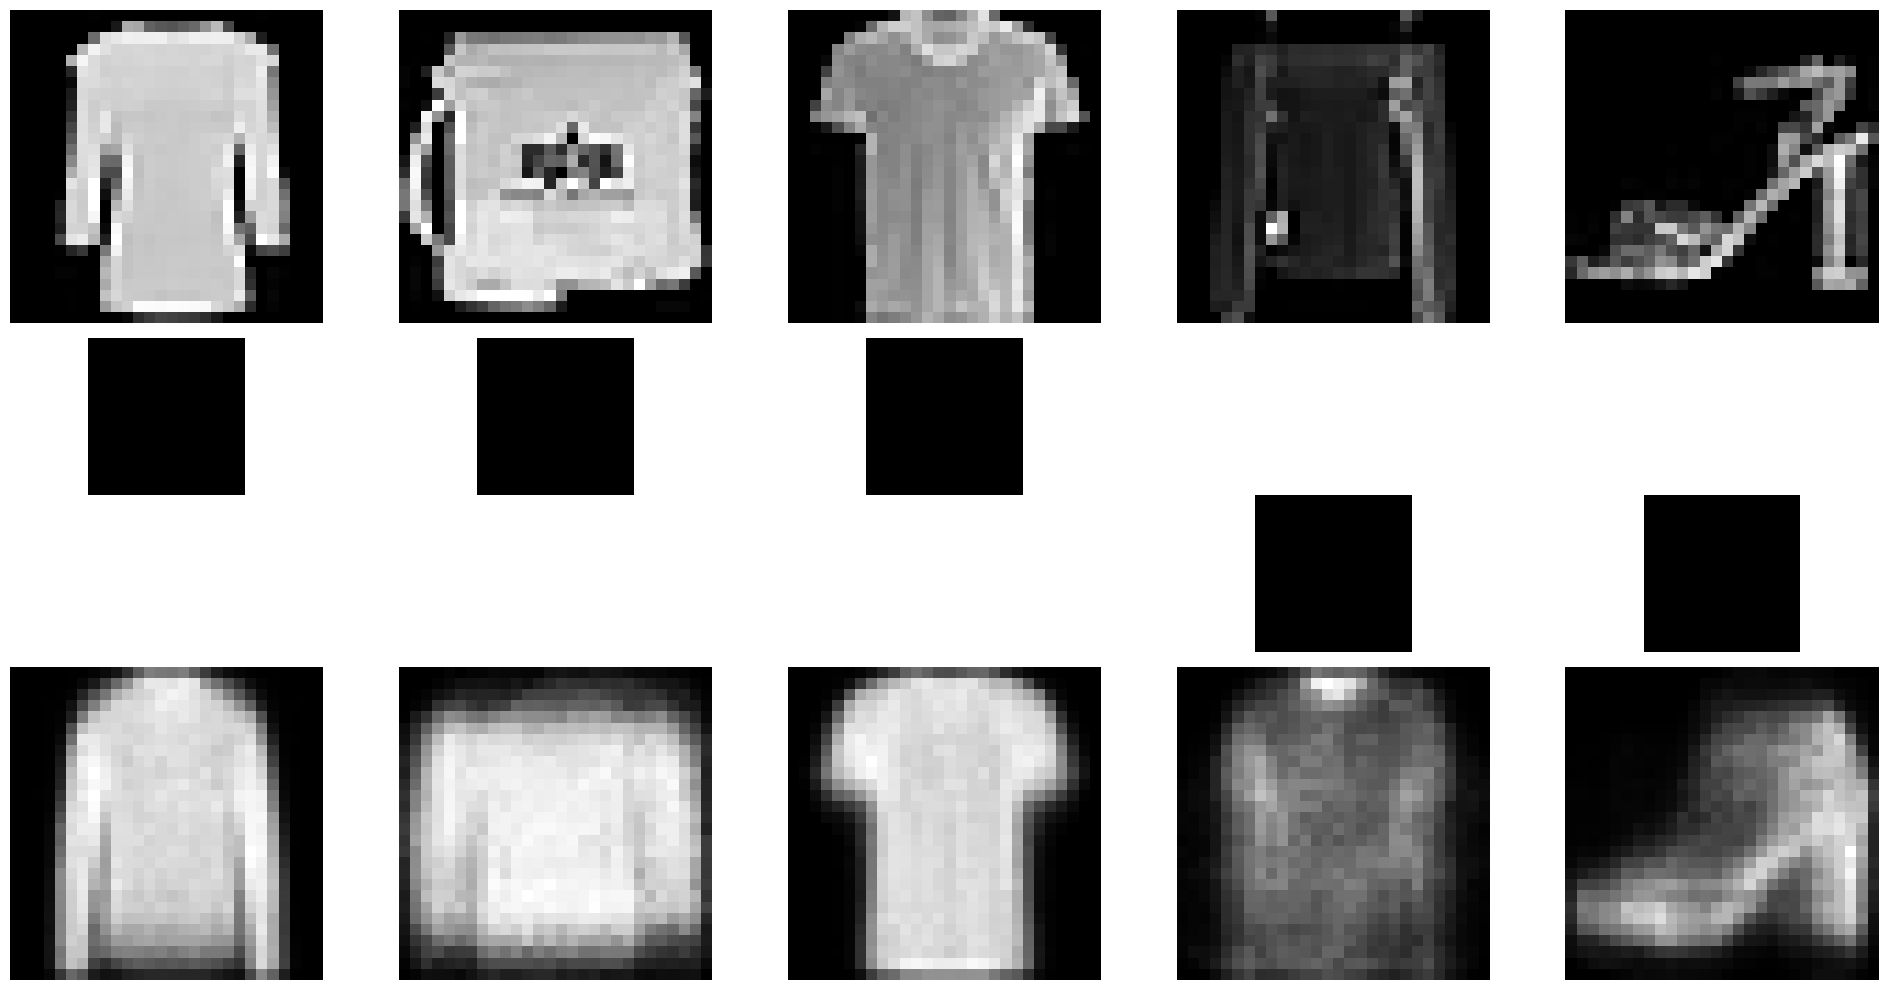

157/157 - 1s - 5ms/step - loss: 0.3314 - rounded_accuracy: 0.8926
Validation loss: 0.3314, Validation accuracy: 0.8926


In [24]:
train(
        ae_2d, X_train, X_valid, epochs=20, batch_size=64,
        filename="../models/autoencoder_2d_model.keras",
        shape=(2, 1)
        )

157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


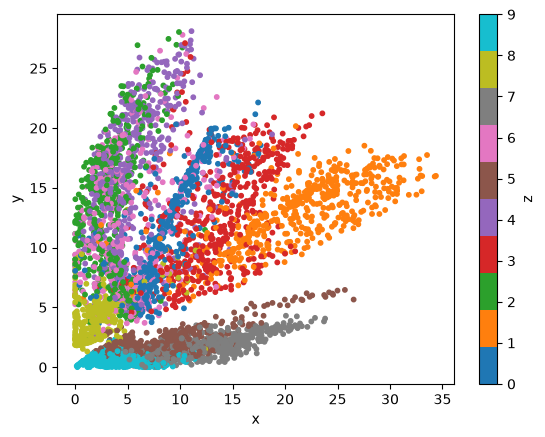

In [26]:
code_2d = encoder_2d.predict(X_valid)

points = code_2d

plt.scatter(points[:, 0], points[:, 1], c=y_valid, cmap="tab10", s=10)
plt.colorbar(label="z")
plt.xlabel("x")
plt.ylabel("y")
plt.show()

157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


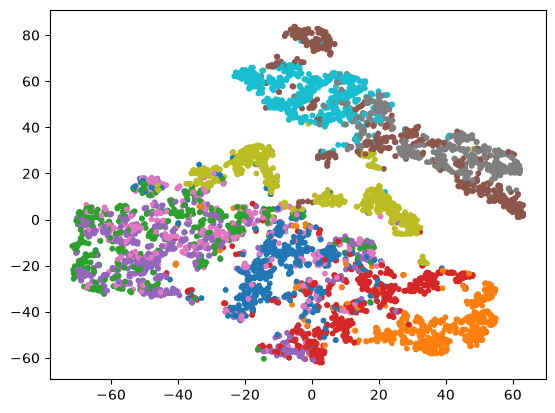

In [27]:
from sklearn.manifold import TSNE

model = keras.models.load_model("../models/autoencoder_model.keras")
encoder = model.layers[0]  # Assuming the encoder is the first layer
X_valid_compressed = encoder.predict(X_valid[:5000])
tsne = TSNE(init="pca", learning_rate="auto", random_state=42)
X_valid_2D = tsne.fit_transform(X_valid_compressed)

plt.scatter(X_valid_2D[:, 0], X_valid_2D[:, 1], c=y_valid[:5000], s=10, cmap="tab10")
plt.show()